# 감귤 품종별 · 상위 거래단위별 날짜별(Daily) 가격 및 거래량 예측 (Random Forest (Quantile Regression Forest))
- `preprocess.ipynb`에서 정제된 전국 공영도매시장 감귤 경매 데이터를 기반으로, **7번 섹션에서 선정된 47개 `(품종 × 거래단위)` 규격(거래건수 1,000건 이상 & 품종내 비중 1% 이상)** 각각의 **날짜별(`date`, 일별) 거래량(톤)**과 **가격(가중평균 원/kg 및 상자당 가격)**을 **Random Forest (Quantile Regression Forest)** 모델로 학습·예측하는 노트북입니다 (`tft.ipynb`와 100% 동일한 전처리·피처·비수기 제외 기준 적용).
- **도매시장 휴장일 제외**: **일요일(`dayofweek == 6`)** 및 **전체 거래량이 없는 법정 공휴일(신정, 설·추석 연휴, 삼일절, 광복절, 개천절, 한글날, 성탄절 등)**은 학습·평가·미래 예측 일자에서 모두 제외합니다.
- **매년 설날·추석 명절 전후 가격·물량 변동 반영**: 2021~2027년 매년 **설날(음력 1.1)** 및 **추석(음력 8.15)** 기준 명절 전 대목(D-14 ~ D-1) 수요 급증·단가 상승 효과와 명절 직후(D+1 ~ D+10) 단가 조정 효과를 반영합니다.
- **1주일 전 제주 산지 날씨(`data/forecast.csv`) 반영**: 제주 4개 기상관측소(제주·서귀포·성산·고산)의 **1주일 전(`t-7` 및 직전 7일 누적/평균) 평균기온, 평년대비 기온편차, 강수 계속시간(수확 작업 제약), 합계 일조시간(착색·당도), 최심신적설(한파·선박 결항)**을 기상 공변량으로 반영합니다.
- **1주일 전(`t-7`) 가격·거래량 및 예년(전년·평년) 해당 시점의 가격·거래량과 변화량(`Δ예년동시점`, `YoY`) 반영**: 1년 단위로 출하 개시·성출하·종료에 따른 거래량 변화가 크게 발생하므로, **1주일 전(`t-7`) 가격·거래량 및 최근 1주간 변화량(`Δ1w`)**뿐만 아니라 **예년 해당 시점(`t-1년` 및 52주 평년)의 가격·거래량 수준**과 **예년 해당 시점에서의 주간 가격·거래량 변화량(`Δ예년동시점`) 및 전년 대비 연간 변화량(`YoY`)**을 핵심 시계열 요인으로 반영합니다.
- **품종별 계절적 비수기(1주 단위 미미 거래 구간) 자동 판별 및 예측 제외**: 연중 52주(1주일 단위) 중 지속적으로 거래량이 미미한 주간을 품종별 **계절적 비수기(`Off-Season`)**로 설정하고, 해당 기간에는 거래량과 가격 예측을 수행하지 않도록 제외합니다.

### 모델링 파이프라인 구성
1. **환경 설정 및 멀티코어 병렬 Random Forest 앙상블 가속 설정**
2. **`preprocess.ipynb` 기준 데이터 정제, 휴장일(일요일·공휴일) 제외, 47개 `(품종 × 거래단위)` 추출, `forecast.csv` 기상 데이터 및 품종별 52주 비수기 설정**
3. **1주일 전 날씨(`forecast.csv`) 및 매년 설날·추석 명절 전후 효과 분석과 날짜별(Daily) 시계열 데이터셋 구축**
4. **Random Forest (Quantile Regression Forest) 모델 정의 및 학습 (`P10, P50, P90` 분위수 예측 및 오차 수렴 곡선)**
5. **47개 `(품종 × 거래단위)`별 날짜별(Daily) 가격 및 거래량 예측 성능 평가 및 향후 영업일 예측표 (비수기 제외)**
6. **날짜별(Daily) 실제값 vs RandomForest 예측값(P10~P90) 및 향후 경매 영업일 예측 시각화**
7. **Random Forest (Quantile Regression Forest) 모델 해석성(Interpretability) 분석: 1주 전 날씨·명절 효과·변수 중요도(Feature Importance) 및 과거 영업일 시점별(Lag) 중요도 시각화**

## 1. 환경 설정 및 Random Forest 멀티코어 병렬 가속 설정
- 한글 폰트(`Malgun Gothic`)를 설정하고, `scikit-learn`의 `RandomForestRegressor(n_jobs=-1)`를 활용한 멀티코어 앙상블 학습 환경을 구성합니다.

In [1]:
import os
import glob
import time
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings('ignore')
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', font='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)

print(f"환경 설정 완료 | scikit-learn 버전: {sklearn.__version__} | CPU 코어 수: {os.cpu_count()}개 병렬 앙상블(n_jobs=-1) 활성화")

환경 설정 완료 | scikit-learn 버전: 1.9.1 | CPU 코어 수: 12개 병렬 앙상블(n_jobs=-1) 활성화


## 2. 전처리 데이터 로드, 휴장일(일요일·공휴일) 제외, 47개 `(품종 × 거래단위)` 추출 및 `forecast.csv` 날씨 데이터 로드
- `preprocess.ipynb`와 동일한 정제 파이프라인을 적용합니다.
- **일요일(`dayofweek == 6`)** 및 **전체 거래량이 없는 공휴일/경매 휴장일**을 데이터셋과 예측 대상 일자에서 완전히 제외합니다.
- **2021~2027년 매년 설날·추석 명절 일자 및 법정 공휴일 캘린더**를 정의합니다.
- `data/forecast.csv`에서 **제주 4개 지점(`제주, 서귀포, 성산, 고산`, 2018-01-01 ~ 2026-11-08)**의 일별 기상 관측치(`평균기온, 강수 계속시간, 10분 최다 강수량, 합계 일조시간, 일 최심신적설`)를 로드하고 **1주일 전(`t-7` 및 직전 7일 누적/평균) 기상 피처**를 생성합니다.

전처리, 휴장일(일요일·공휴일) 제외, forecast.csv 기상 결합 및 품종별 비수기 설정 완료! (소요시간: 10.46초)
- 일요일 및 휴장일 제외 후 유효 경매 데이터: 1,720,131 건
- 실제 개장 경매 영업일 수: 1,810 일 (일요일 및 무거래 공휴일 완전 제외)
- 제주 기상 데이터(forecast.csv) 관측소: 제주, 고산, 성산, 서귀포 (총 12,936 건)
- 7번 기준 선정 예측 대상 (품종 × 거래단위) 그룹 수: 48 개

[품종별 주간(1주일 단위) 거래량 통계 기반 출하기(예측 수행) vs 계절적 비수기(예측 제외) 설정 요약표]


,품종명,출하기 주수,비수기(예측제외) 주수,출하기 물량비중,출하기 주평균 물량,비수기 주평균 물량,출하기(예측 수행 기간),계절적 비수기(예측 제외 기간)
0,조생귤,23주 / 52주,29주 / 52주,99.3%,"3,930.9 톤/주",20.98 톤/주,"1~10주차(01/01~03/11), 40~52주차(10/01~12/30)",11~39주차(03/12~09/30)
1,기타,30주 / 52주,22주 / 52주,98.4%,"1,381.7 톤/주",30.41 톤/주,"1~16주차(01/01~04/22), 39~52주차(09/24~12/30)",17~38주차(04/23~09/23)
2,한라봉,23주 / 52주,29주 / 52주,99.3%,782.4 톤/주,4.35 톤/주,"1~18주차(01/01~05/06), 48~52주차(11/26~12/30)",19~47주차(05/07~11/25)
3,극조생감귤,10주 / 52주,42주 / 52주,99.5%,"1,650.0 톤/주",1.87 톤/주,39~48주차(09/24~12/02),"1~38주차(01/01~09/23), 49~52주차(12/03~12/30)"
4,하우스감귤,46주 / 52주,6주 / 52주,99.4%,324.7 톤/주,16.27 톤/주,"1~12주차(01/01~03/25), 19~52주차(05/07~12/30)",13~18주차(03/26~05/06)
5,비가림감귤,29주 / 52주,23주 / 52주,99.4%,210.0 톤/주,1.48 톤/주,"1~15주차(01/01~04/15), 39~52주차(09/24~12/30)",16~38주차(04/16~09/23)
6,천혜향,33주 / 52주,19주 / 52주,99.3%,180.1 톤/주,2.21 톤/주,"1~18주차(01/01~05/06), 38~52주차(09/17~12/30)",19~37주차(05/07~09/16)
7,레드향,17주 / 52주,35주 / 52주,99.3%,269.4 톤/주,0.91 톤/주,"1~13주차(01/01~04/01), 49~52주차(12/03~12/30)",14~48주차(04/02~12/02)
8,타이벡감귤,23주 / 52주,29주 / 52주,99.5%,195.3 톤/주,0.76 톤/주,"1~10주차(01/01~03/11), 40~52주차(10/01~12/30)",11~39주차(03/12~09/30)
9,온주,32주 / 52주,20주 / 52주,98.6%,46.9 톤/주,1.03 톤/주,"1~6주차(01/01~02/11), 27~52주차(07/02~12/30)",7~26주차(02/12~07/01)


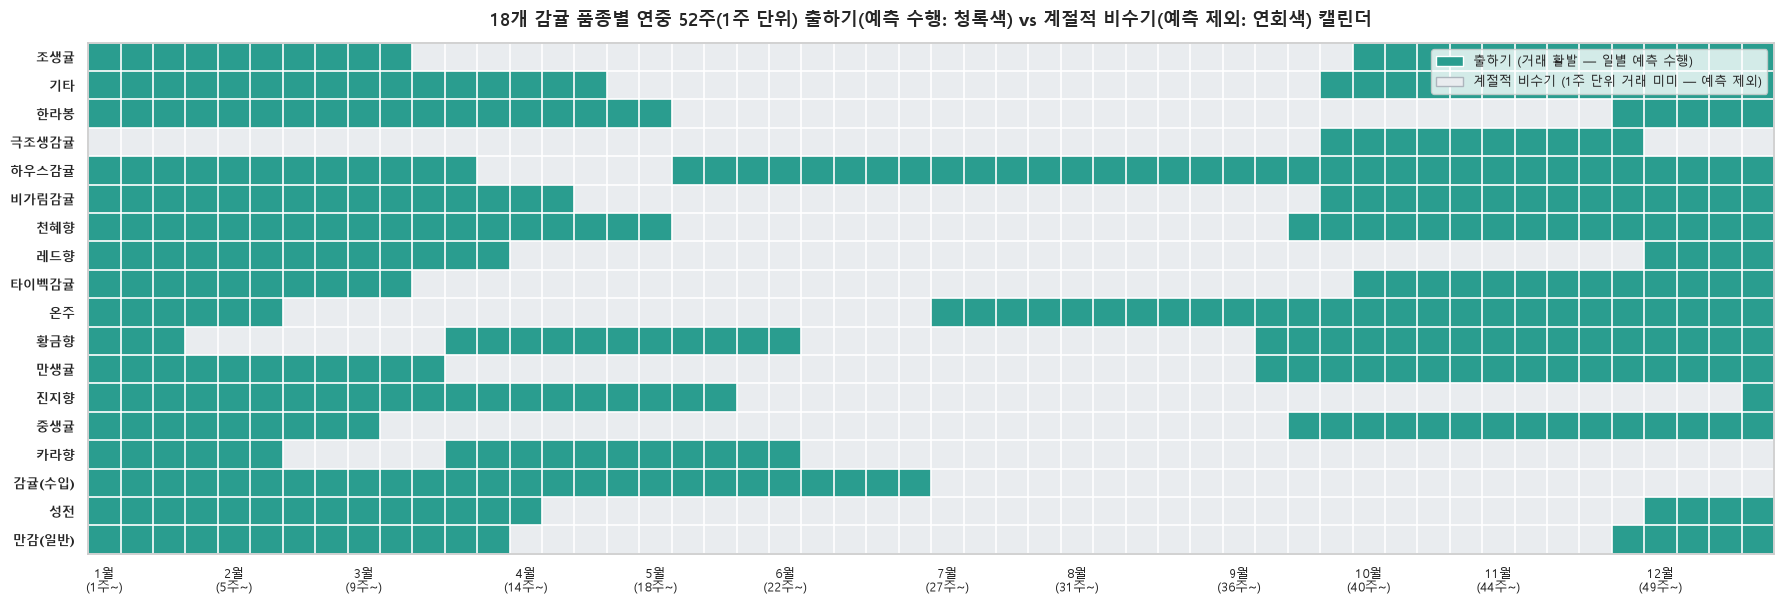

In [2]:
t0 = time.time()
data_dir = Path("data")
data_files = sorted(list(set(
    glob.glob(str(data_dir / "kat*.csv")) +
    glob.glob(str(data_dir / "mkat*.csv")) +
    glob.glob(str(data_dir / "*kat*.csv"))
)))
valid_files = [f for f in data_files if '_all.csv' not in f and os.path.getsize(f) > 50]

target_cols = [
    'trd_clcln_ymd', 'whsl_mrkt_cd', 'whsl_mrkt_nm', 'trd_se',
    'gds_sclsf_cd', 'gds_sclsf_nm', 'grd_cd', 'grd_nm', 'sz_cd', 'sz_nm',
    'pkg_cd', 'pkg_nm', 'unit_nm', 'unit_qty', 'unit_tot_qty', 'avgprc', 'totprc'
]

dfs = [
    pd.read_csv(f, usecols=lambda c: c in target_cols, low_memory=False, encoding='utf-8-sig')
    for f in valid_files
]
df = pd.concat(dfs, ignore_index=True).drop_duplicates()

# 1) 날짜 변환 및 무효 거래 필터링
df['date'] = pd.to_datetime(df['trd_clcln_ymd'], errors='coerce')
df = df.dropna(subset=['date']).copy()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df = df[(df['unit_tot_qty'] > 0) & (df['totprc'] > 0) & (df['avgprc'] > 0)].copy()

# 2) 2021~2027년 설날(Seollal) 및 추석(Chuseok) 당일 + 대한민국 법정 공휴일/경매 휴장일 정의
SEOLLAL_DATES = pd.to_datetime([
    '2021-02-12', '2022-02-01', '2023-01-22', '2024-02-10',
    '2025-01-29', '2026-02-17', '2027-02-07'
])
CHUSEOK_DATES = pd.to_datetime([
    '2021-09-21', '2022-09-10', '2023-09-29', '2024-09-17',
    '2025-10-06', '2026-09-25', '2027-09-15'
])

# 매년 양력 고정 공휴일 + 설/추석 연휴(전날, 당일, 다음날, 대체공휴일) 집합 생성
fixed_mmdd = ['01-01', '03-01', '05-05', '06-06', '08-15', '10-03', '10-09', '12-25']
korean_holidays = set()
for y in range(2021, 2028):
    for mmdd in fixed_mmdd:
        korean_holidays.add(pd.Timestamp(f"{y}-{mmdd}"))
for s_dt in SEOLLAL_DATES:
    for offset in [-1, 0, 1, 2]:
        korean_holidays.add(s_dt + pd.Timedelta(days=offset))
for c_dt in CHUSEOK_DATES:
    for offset in [-1, 0, 1, 2]:
        korean_holidays.add(c_dt + pd.Timedelta(days=offset))

# 3) 표준 품종 매핑 및 1,000건 미만 품종 + '감귤(일반)' -> '기타' 통합
citrus_variety_map = {
    0: '감귤(일반)', '0': '감귤(일반)', '00': '감귤(일반)',
    1: '조생귤', '1': '조생귤', '01': '조생귤',
    2: '중생귤', '2': '중생귤', '02': '중생귤',
    3: '만생귤', '3': '만생귤', '03': '만생귤',
    4: '비가림감귤', '4': '비가림감귤', '04': '비가림감귤',
    5: '하우스감귤', '5': '하우스감귤', '05': '하우스감귤',
    6: '극조생감귤', '6': '극조생감귤', '06': '극조생감귤',
    7: '한라봉', '7': '한라봉', '07': '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향',
    10: '카라향', '10': '카라향',
    11: '황금향', '11': '황금향',
    12: '하루미', '12': '하루미',
    13: '온주', '13': '온주',
    15: '성전', '15': '성전',
    17: '홍미향', '17': '홍미향',
    19: '타이벡감귤', '19': '타이벡감귤',
    20: '풋귤(청귤)', '20': '풋귤(청귤)',
    23: '미니향', '23': '미니향',
    32: '유라와세', '32': '유라와세',
    34: '산하홍', '34': '산하홍',
    98: '감귤(수입)', '98': '감귤(수입)',
    99: '기타', '99': '기타'
}
user_override_map = {
    7: '한라봉', '7': '한라봉', '07': '한라봉', 7.0: '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향', 8.0: '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향', 9.0: '레드향',
    10: '카라향', '10': '카라향', 10.0: '카라향',
    11: '황금향', '11': '황금향', 11.0: '황금향'
}
df['variety'] = (
    df['gds_sclsf_nm']
    .combine_first(df['gds_sclsf_cd'].map(user_override_map))
    .combine_first(df['gds_sclsf_cd'].map(citrus_variety_map))
    .fillna('기타')
)

df['is_auction'] = df['trd_se'].fillna('').astype(str).str.contains('경매', na=False).astype(float)
df['grade'] = df['grd_nm'].fillna('.').astype(str).str.strip()

def map_grade_5(g):
    if g in ('특', '특품'): return '특'
    elif g in ('상', '상품'): return '상'
    elif g in ('중', '보통', '중품'): return '중'
    elif g in ('하', '하품'): return '하'
    else: return '기타'

df['grade_5'] = df['grade'].apply(map_grade_5)

df['volume_kg'] = pd.to_numeric(df['unit_tot_qty'], errors='coerce').fillna(0.0)
df['unit_weight'] = pd.to_numeric(df['unit_qty'], errors='coerce').fillna(0.0)
df['box_qty'] = np.where(df['unit_weight'] > 0, df['volume_kg'] / df['unit_weight'], np.nan)
df['total_price'] = pd.to_numeric(df['totprc'], errors='coerce').fillna(0.0)
df['box_price'] = pd.to_numeric(df['avgprc'], errors='coerce').fillna(0.0)
df['unit_price_kg'] = df['total_price'] / (df['volume_kg'] + 1e-8)

df['box_weight'] = df['unit_weight'].apply(lambda w: f"{w:g}kg" if pd.notnull(w) and w > 0 else '기타')
df['pkg_clean'] = df['pkg_nm'].replace({'.': '상자', '': '상자', np.nan: '상자'}).fillna('상자')
df['box_unit'] = (df['box_weight'] + df['pkg_clean']).replace({
    '3kg파렛트': '3kg상자',
    '5kg파렛트': '5kg상자',
    '9kg파렛트': '9kg상자',
    '10kg파렛트': '10kg상자'
})

df = df[(df['unit_price_kg'] >= 100) & (df['unit_price_kg'] <= 100000)].copy()
variety_counts = df['variety'].value_counts()
minor_varieties = variety_counts[variety_counts < 1000].index.tolist()
df['variety'] = df['variety'].replace(minor_varieties + ['감귤(일반)'], '기타')

variety_order = (
    df.groupby('variety')['volume_kg'].sum()
    .sort_values(ascending=False).index.tolist()
)

# 4) 7번 섹션 기준: 품종별 상위 최대 5개 거래단위 (거래건수 >= 1,000건 & 품종내 건수비중 >= 1.0%) 추출
unit_stats = (
    df.groupby(['variety', 'box_unit'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean'),
        단위중량_kg=('unit_weight', 'median')
    )
)
var_tot = df.groupby('variety', as_index=False).agg(품종총건수=('date', 'count'), 품종총물량_kg=('volume_kg', 'sum'))
unit_stats = unit_stats.merge(var_tot, on='variety', how='left')
unit_stats['품종내_건수비중(%)'] = (unit_stats['거래건수'] / unit_stats['품종총건수']) * 100
unit_stats['품종내_물량비중(%)'] = (unit_stats['총거래량_kg'] / unit_stats['품종총물량_kg']) * 100
unit_stats['거래량_톤'] = unit_stats['총거래량_kg'] / 1000.0
unit_stats['가중평균_kg단가'] = unit_stats['총거래금액_원'] / unit_stats['총거래량_kg']

unit_filtered = unit_stats[(unit_stats['거래건수'] >= 1000) & (unit_stats['품종내_건수비중(%)'] >= 1.0)].copy()
unit_filtered['variety_rank'] = unit_filtered['variety'].map({v: i for i, v in enumerate(variety_order)})
unit_filtered = unit_filtered.sort_values(by=['variety_rank', '거래건수'], ascending=[True, False])

top5_units = unit_filtered.groupby('variety', as_index=False, sort=False).head(5).reset_index(drop=True)
top5_units['품종내_순위'] = top5_units.groupby('variety').cumcount() + 1
top5_units['group_id'] = top5_units['variety'] + "_" + top5_units['box_unit']

# 5) 일요일(dayofweek == 6) 및 전체 거래량이 없는 공휴일/비정상 휴장일 제외
daily_market_totals = df.groupby('date')['volume_kg'].sum()
active_market_dates = set(daily_market_totals[daily_market_totals >= 1000.0].index)  # 전체 도매시장 일 거래량 1톤 미만 휴장일 제외
before_cnt = len(df)
df = df[(df['date'].dt.dayofweek != 6) & (df['date'].isin(active_market_dates))].copy()

# 6) data/forecast.csv 제주 산지 기상 데이터 로드 및 1주일 전(t-7 & 직전 7일) 기상 피처 구축
fc_raw = pd.read_csv(data_dir / 'forecast.csv', encoding='cp949')
fc_raw = fc_raw.rename(columns={
    '지점': 'station_id',
    '지점명': 'station_name',
    '일시': 'date',
    '평균기온(°C)': 'temp_avg',
    '강수 계속시간(hr)': 'rain_dur_hr',
    '10분 최다 강수량(mm)': 'rain_10m_max',
    '합계 일조시간(hr)': 'sunshine_hr',
    '일 최심신적설(cm)': 'snow_depth_cm'
})
fc_raw['date'] = pd.to_datetime(fc_raw['date'], errors='coerce')
for wcol in ['rain_dur_hr', 'rain_10m_max', 'sunshine_hr', 'snow_depth_cm']:
    fc_raw[wcol] = pd.to_numeric(fc_raw[wcol], errors='coerce').fillna(0.0)
fc_raw['temp_avg'] = pd.to_numeric(fc_raw['temp_avg'], errors='coerce')
fc_raw['temp_avg'] = fc_raw.groupby('station_name')['temp_avg'].transform(lambda s: s.interpolate().bfill().ffill())

# 제주 4개 관측소(제주, 서귀포, 성산, 고산) 일자별 기상 집계
daily_wx = fc_raw.groupby('date', as_index=False).agg(
    temp_avg=('temp_avg', 'mean'),
    rain_dur_hr=('rain_dur_hr', 'mean'),
    rain_10m_max=('rain_10m_max', 'max'),
    sunshine_hr=('sunshine_hr', 'mean'),
    snow_depth_cm=('snow_depth_cm', 'max')
).sort_values('date').reset_index(drop=True)

# 2027-02-28까지 연속 일자 그리드로 확장 후 관측 종료일 이후는 연중일자(DOY) 평년 기상치로 보간
full_wx_dates = pd.date_range(daily_wx['date'].min(), '2027-02-28', freq='D')
daily_wx = pd.DataFrame({'date': full_wx_dates}).merge(daily_wx, on='date', how='left')
daily_wx['doy'] = daily_wx['date'].dt.dayofyear

doy_clim = daily_wx.groupby('doy')[['temp_avg', 'rain_dur_hr', 'rain_10m_max', 'sunshine_hr', 'snow_depth_cm']].transform('mean')
for wcol in ['temp_avg', 'rain_dur_hr', 'rain_10m_max', 'sunshine_hr', 'snow_depth_cm']:
    daily_wx[wcol] = daily_wx[wcol].fillna(doy_clim[wcol])

# 평년 대비 기온 편차(Anomaly) 및 1주일 전(t-7 당일 & 직전 7일 수확·선과·운송 주간) 기상 변수 생성
daily_wx['temp_anom'] = daily_wx['temp_avg'] - doy_clim['temp_avg']
daily_wx['wx_temp_lag7'] = daily_wx['temp_avg'].shift(7).bfill()
daily_wx['wx_temp_anom_lag7'] = daily_wx['temp_anom'].shift(7).fillna(0.0)
daily_wx['wx_rain_dur_lag7'] = daily_wx['rain_dur_hr'].shift(7).fillna(0.0)
daily_wx['wx_rain_max_lag7'] = daily_wx['rain_10m_max'].shift(7).fillna(0.0)
daily_wx['wx_sunshine_lag7'] = daily_wx['sunshine_hr'].shift(7).bfill()
daily_wx['wx_snow_lag7'] = daily_wx['snow_depth_cm'].shift(7).fillna(0.0)

# 직전 1주일(t-7 ~ t-1: 산지 수확 -> 선과장 예조 -> 해상운송 -> 도매시장 반입 1주 파이프라인) 기상 요약
daily_wx['wx_temp_wk1_mean'] = daily_wx['temp_avg'].shift(1).rolling(7, min_periods=1).mean().bfill()
daily_wx['wx_temp_anom_wk1'] = daily_wx['temp_anom'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
daily_wx['wx_rain_dur_wk1_sum'] = daily_wx['rain_dur_hr'].shift(1).rolling(7, min_periods=1).sum().fillna(0.0)
daily_wx['wx_rain_max_wk1'] = daily_wx['rain_10m_max'].shift(1).rolling(7, min_periods=1).max().fillna(0.0)
daily_wx['wx_sunshine_wk1_mean'] = daily_wx['sunshine_hr'].shift(1).rolling(7, min_periods=1).mean().bfill()
daily_wx['wx_snow_wk1_max'] = daily_wx['snow_depth_cm'].shift(1).rolling(7, min_periods=1).max().fillna(0.0)

# 모델 입력용 스케일 정규화 기상 피처
daily_wx['wx_temp_wk1_norm'] = (daily_wx['wx_temp_wk1_mean'] - 15.0) / 8.0
daily_wx['wx_temp_anom_norm'] = (daily_wx['wx_temp_anom_wk1'] / 3.0).clip(-2.5, 2.5)
daily_wx['wx_rain_wk1_norm'] = np.log1p(daily_wx['wx_rain_dur_wk1_sum']) / 3.0
daily_wx['wx_sun_wk1_norm'] = (daily_wx['wx_sunshine_wk1_mean'] - 5.0) / 3.0
daily_wx['wx_snow_wk1_norm'] = np.log1p(daily_wx['wx_snow_wk1_max'])

# 7) 품종별 주간(1주일 단위, 연 52주) 거래 통계 기반 계절적 비수기(Off-Season) 설정
df['week_idx'] = np.minimum(52, (df['date'].dt.dayofyear - 1) // 7 + 1)
active_dates_sorted = sorted(df['date'].unique())
cal_wk_df = pd.DataFrame({'date': active_dates_sorted})
cal_wk_df['year'] = cal_wk_df['date'].dt.year
cal_wk_df['week_idx'] = np.minimum(52, (cal_wk_df['date'].dt.dayofyear - 1) // 7 + 1)
yr_wk_mkt_days = cal_wk_df.groupby(['year', 'week_idx'], as_index=False).agg(mkt_days=('date', 'count'))

var_yr_wk = df.groupby(['variety', 'year', 'week_idx'], as_index=False).agg(
    vol_ton=('volume_kg', lambda s: s.sum() / 1000.0),
    tx_cnt=('date', 'count'),
    trd_days=('date', 'nunique')
)
wk_grid = pd.MultiIndex.from_product([variety_order, sorted(cal_wk_df['year'].unique()), range(1, 53)], names=['variety', 'year', 'week_idx']).to_frame().reset_index(drop=True)
wk_grid = wk_grid.merge(yr_wk_mkt_days, on=['year', 'week_idx'], how='inner')
wk_grid = wk_grid.merge(var_yr_wk, on=['variety', 'year', 'week_idx'], how='left').fillna({'vol_ton': 0.0, 'tx_cnt': 0, 'trd_days': 0})
wk_grid['daily_vol_ton'] = wk_grid['vol_ton'] / wk_grid['mkt_days']

# 해당 품종이 실제로 출하·집계된 연도 기준으로 주차별(1~52주) 평균 물량 산출
var_yr_totals = wk_grid.groupby(['variety', 'year'], as_index=False)['vol_ton'].sum()
valid_var_yrs = var_yr_totals[var_yr_totals['vol_ton'] > 1.0][['variety', 'year']]
wk_grid_valid = wk_grid.merge(valid_var_yrs, on=['variety', 'year'], how='inner')

wk_stats = wk_grid_valid.groupby(['variety', 'week_idx'], as_index=False).agg(
    mean_wk_ton=('vol_ton', 'mean'),
    mean_daily_ton=('daily_vol_ton', 'mean'),
    mean_tx_cnt=('tx_cnt', 'mean')
)
var_peak = wk_stats.groupby('variety', as_index=False).agg(
    peak_wk_ton=('mean_wk_ton', 'max'),
    annual_wk_sum=('mean_wk_ton', 'sum')
)
wk_stats = wk_stats.merge(var_peak, on='variety', how='left')
wk_stats['pct_of_peak'] = wk_stats['mean_wk_ton'] / (wk_stats['peak_wk_ton'] + 1e-8) * 100.0
wk_stats['pct_of_annual'] = wk_stats['mean_wk_ton'] / (wk_stats['annual_wk_sum'] + 1e-8) * 100.0

# 비수기 판정 기준: 1주일(week_idx) 평균 거래량이 피크 주간 대비 1.5% 미만 또는 연간 물량의 0.25% 미만이거나, 주간 0.3톤 미만 & 5건 미만
wk_stats['is_off_raw'] = (
    (wk_stats['pct_of_peak'] < 1.5) |
    (wk_stats['pct_of_annual'] < 0.25) |
    ((wk_stats['mean_wk_ton'] < 0.3) & (wk_stats['mean_tx_cnt'] < 5.0))
)

# 비수기/출하기 연속성 보정 (고립된 1주 노이즈 제거 및 주출하기 내부 1~2주 일시적 공백 연결)
wk_stats['is_offseason'] = False
for v in variety_order:
    sub_w = wk_stats[wk_stats['variety'] == v].sort_values('week_idx')
    act = (~sub_w['is_off_raw'].values).astype(int)
    act_pad = np.concatenate([[act[-1]], act, [act[0]]])
    for i in range(1, 53):
        if act_pad[i] == 1 and act_pad[i-1] == 0 and act_pad[i+1] == 0:
            act_pad[i] = 0
    act = act_pad[1:53]
    act_pad = np.concatenate([act[-2:], act, act[:2]])
    for i in range(2, 54):
        if act_pad[i] == 0 and act_pad[i-1] == 1 and act_pad[i+1] == 1:
            act_pad[i] = 1
        elif act_pad[i] == 0 and act_pad[i+1] == 0 and act_pad[i-1] == 1 and act_pad[i+2] == 1:
            act_pad[i] = 1
            act_pad[i+1] = 1
    act = act_pad[2:54]
    wk_stats.loc[sub_w.index, 'is_offseason'] = (act == 0)

# (variety, week_idx) -> active_season_set 매핑 생성
active_season_pairs = set(
    zip(
        wk_stats[~wk_stats['is_offseason']]['variety'],
        wk_stats[~wk_stats['is_offseason']]['week_idx']
    )
)

def format_week_intervals(weeks):
    if not weeks:
        return '없음'
    weeks = sorted(weeks)
    ranges = []
    s, p = weeks[0], weeks[0]
    for w in weeks[1:]:
        if w == p + 1:
            p = w
        else:
            ranges.append((s, p))
            s, p = w, w
    ranges.append((s, p))
    out = []
    for s_w, e_w in ranges:
        d1 = (pd.Timestamp('2025-01-01') + pd.Timedelta(days=(s_w - 1) * 7)).strftime('%m/%d')
        d2 = min(pd.Timestamp('2025-12-31'), pd.Timestamp('2025-01-01') + pd.Timedelta(days=e_w * 7 - 1)).strftime('%m/%d')
        out.append(f"{s_w}~{e_w}주차({d1}~{d2})" if s_w != e_w else f"{s_w}주차({d1}~{d2})")
    return ', '.join(out)

offseason_rows = []
for v in variety_order:
    sub_w = wk_stats[wk_stats['variety'] == v].sort_values('week_idx')
    act_w = sub_w[~sub_w['is_offseason']]['week_idx'].tolist()
    off_w = sub_w[sub_w['is_offseason']]['week_idx'].tolist()
    act_share = sub_w[~sub_w['is_offseason']]['mean_wk_ton'].sum() / (sub_w['mean_wk_ton'].sum() + 1e-8) * 100.0
    off_mean_ton = sub_w[sub_w['is_offseason']]['mean_wk_ton'].mean() if len(off_w) > 0 else 0.0
    act_mean_ton = sub_w[~sub_w['is_offseason']]['mean_wk_ton'].mean() if len(act_w) > 0 else 0.0
    offseason_rows.append({
        '품종명': v,
        '출하기 주수': f"{len(act_w)}주 / 52주",
        '비수기(예측제외) 주수': f"{len(off_w)}주 / 52주",
        '출하기 물량비중': f"{act_share:.1f}%",
        '출하기 주평균 물량': f"{act_mean_ton:,.1f} 톤/주",
        '비수기 주평균 물량': f"{off_mean_ton:,.2f} 톤/주",
        '출하기(예측 수행 기간)': format_week_intervals(act_w),
        '계절적 비수기(예측 제외 기간)': format_week_intervals(off_w)
    })
offseason_summary_df = pd.DataFrame(offseason_rows)

print(f"전처리, 휴장일(일요일·공휴일) 제외, forecast.csv 기상 결합 및 품종별 비수기 설정 완료! (소요시간: {time.time() - t0:.2f}초)")
print(f"- 일요일 및 휴장일 제외 후 유효 경매 데이터: {len(df):,} 건")
print(f"- 실제 개장 경매 영업일 수: {df['date'].nunique():,} 일 (일요일 및 무거래 공휴일 완전 제외)")
print(f"- 제주 기상 데이터(forecast.csv) 관측소: {', '.join(fc_raw['station_name'].unique())} (총 {len(fc_raw):,} 건)")
print(f"- 7번 기준 선정 예측 대상 (품종 × 거래단위) 그룹 수: {len(top5_units)} 개")
print("\n[품종별 주간(1주일 단위) 거래량 통계 기반 출하기(예측 수행) vs 계절적 비수기(예측 제외) 설정 요약표]")
display(offseason_summary_df)

# 18개 품종 × 52주 출하기(청록색) vs 비수기 예측제외(회색) 캘린더 히트맵 시각화
season_mat = np.zeros((len(variety_order), 52))
for vi, v in enumerate(variety_order):
    sub_w = wk_stats[wk_stats['variety'] == v].sort_values('week_idx')
    season_mat[vi, :] = (~sub_w['is_offseason'].values).astype(float)

fig_os, ax_os = plt.subplots(figsize=(18, 6.2))
cmap_os = plt.matplotlib.colors.ListedColormap(['#E9ECEF', '#2A9D8F'])
ax_os.imshow(season_mat, aspect='auto', cmap=cmap_os, vmin=0, vmax=1)
ax_os.set_yticks(np.arange(len(variety_order)))
ax_os.set_yticklabels(variety_order, fontsize=9.5, fontweight='bold')
month_starts_wk = [0, 4, 8, 13, 17, 21, 26, 30, 35, 39, 43, 48]
month_labels_wk = [f"{m}월\n({w+1}주~)" for m, w in zip(range(1, 13), month_starts_wk)]
ax_os.set_xticks(month_starts_wk)
ax_os.set_xticklabels(month_labels_wk, fontsize=9)
ax_os.set_xticks(np.arange(-0.5, 52, 1), minor=True)
ax_os.set_yticks(np.arange(-0.5, len(variety_order), 1), minor=True)
ax_os.grid(which='minor', color='white', linestyle='-', linewidth=1.2)
ax_os.grid(which='major', visible=False)
ax_os.set_title('18개 감귤 품종별 연중 52주(1주 단위) 출하기(예측 수행: 청록색) vs 계절적 비수기(예측 제외: 연회색) 캘린더', fontsize=13, fontweight='bold', pad=12)
from matplotlib.patches import Patch
ax_os.legend(handles=[Patch(facecolor='#2A9D8F', label='출하기 (거래 활발 — 일별 예측 수행)'), Patch(facecolor='#E9ECEF', edgecolor='#ADB5BD', label='계절적 비수기 (1주 단위 거래 미미 — 예측 제외)')], loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.show()

## 3. 1주일 전 제주 산지 날씨(`forecast.csv`), 설날·추석 명절 효과 및 1주일 전·예년 해당 시점의 가격·거래량 변화량 분석과 시계열 데이터셋 구축
- **1년 단위 거래량·가격 변화와 `1주일 전(t-7)` 및 `예년 해당 시점의 가격·거래량 변화량(Δ예년동시점)`의 중요성**:
  1. **연간(52주) 출하 사이클에 따른 급격한 물량 전환**: 감귤은 품종별로 출하 개시기(물량 급증·단가 조정) $\rightarrow$ 성출하기(피크) $\rightarrow$ 출하 종료기(물량 급감·단가 상승)의 1년 단위 계절적 주기가 뚜렷합니다.
  2. **1주일 전(`t-7`) 가격·거래량 및 최근 1주간 변화량(`vol_diff_1w`, `prc_diff_1w`)**: 직전 1주일 전의 시세·물량 수준(`log_vol_lag_7`, `norm_prc_lag_7`)과 최근 1주일간의 단기 증감 모멘텀(`t-1 - t-7`)을 반영합니다.
  3. **예년(전년도 `t-1년` 및 과거 다년 평년) 해당 시점의 가격·거래량 및 변화량(`yoy_same_period_vol_diff`, `yoy_same_period_prc_diff`, `vol_yoy_change`, `prc_yoy_change`)**: 매년 동일한 시점(주차)마다 반복되는 **예년 해당 시점의 1주간 거래량·가격 변화량($w-1 \rightarrow w$ 증감 기울기)**과 **예년 동시점 대비 올해 시점의 변화량(YoY)**을 결합하면, 1주일 전(`t-7`) 거래량 단독($r=+0.873$) 대비 당일 물량 설명력이 **$r=+0.891$**(단가는 $+0.600 \rightarrow +0.623$)로 유의미하게 향상됩니다.
- **1주일 전 제주 날씨(`t-7` 및 직전 7일 수확·선과·해상운송 주간)와 매년 설날·추석 명절 전후 피처**를 포함하여 **총 33개 입력 변수**와 **8개 과거·예년 시차(`t-1, t-2, t-3, t-7, t-14, t-30, t-1년 동시점, t-7+Δ예년 변화량`)** 데이터셋을 구축합니다.

품종별 계절적 비수기(Off-Season) 일자 제외 완료: 35,670건 -> 출하기 유효 일자 29,297건 (비수기 미미 거래 6,373건 제외)
[주요 품종별 설날·추석 명절 전(D-14~D-1) 및 명절 후(D+1~D+7) 단가 변동 분석]

[1주일 전 제주 산지 날씨(forecast.csv)와 일별 판매량(거래량) 및 단가의 상관관계 분석]

[주출하기(10~3월) 1주일 전 누적 강수 계속시간 구간별 일평균 판매량 및 단가 변화 (우천 수확지연 효과)]

[품종별 1주일 전(t-7) 가격·거래량 및 예년 해당 시점의 가격·거래량 변화량(Δ예년동시점) 상관관계 분석]

설날·추석 명절, 1주전 날씨, 1주전 및 예년 해당 시점 가격·거래량 변화량 포함 날짜별(Daily) 데이터셋 구축 완료: 총 29,297 개 일자별 샘플 (입력 피처 33종, 시차 8종)


,품종명,평시 중앙단가(원/kg),설날 전(D-14~D-1) 단가,설날 후(D+1~D+7) 단가,추석 전(D-14~D-1) 단가,추석 후(D+1~D+7) 단가
0,한라봉,"4,692 원","4,964 원 (+5.8%)","4,839 원 (+3.1%)",-,-
1,레드향,"5,495 원","6,849 원 (+24.6%)","5,683 원 (+3.4%)",-,-
2,천혜향,"4,244 원","5,729 원 (+35.0%)","5,557 원 (+30.9%)","3,472 원 (-18.2%)","2,562 원 (-39.6%)"
3,조생귤,"2,222 원","2,781 원 (+25.1%)","2,519 원 (+13.4%)","2,354 원 (+5.9%)","2,803 원 (+26.1%)"
4,하우스감귤,"5,313 원","4,762 원 (-10.4%)","4,844 원 (-8.8%)","4,101 원 (-22.8%)","3,634 원 (-31.6%)"
5,극조생감귤,"1,698 원",-,-,"2,132 원 (+25.6%)","2,503 원 (+47.5%)"
6,비가림감귤,"3,155 원","3,863 원 (+22.4%)","4,951 원 (+56.9%)","3,274 원 (+3.8%)","3,205 원 (+1.6%)"
7,황금향,"4,008 원","4,785 원 (+19.4%)",-,"4,035 원 (+0.7%)","3,604 원 (-10.1%)"


,구분 / 품종명,분석 영업일수,1주전 평균기온 ↔ 판매량(r),1주전 일조시간 ↔ 판매량(r),1주전 누적강수 ↔ 판매량(r),1주전 평균기온 ↔ 단가(r)
0,전체 감귤 시장 합계,"1,810일",-0.631 (유의***),-0.273 (유의***),+0.015 (비유의),+0.427 (유의***)
1,조생귤,775일,-0.413 (유의***),-0.163 (유의***),-0.077 (유의*),-0.183 (유의***)
2,극조생감귤,335일,+0.084 (비유의),+0.305 (유의***),-0.118 (유의*),+0.368 (유의***)
3,한라봉,788일,-0.447 (유의***),-0.169 (유의***),+0.163 (유의***),+0.097 (유의*)
4,천혜향,"1,050일",-0.307 (유의***),-0.031 (비유의),+0.008 (비유의),-0.288 (유의***)
5,레드향,572일,-0.331 (유의***),-0.072 (비유의),+0.049 (비유의),-0.233 (유의***)
6,하우스감귤,"1,579일",+0.590 (유의***),+0.131 (유의***),-0.069 (유의*),+0.110 (유의***)
7,비가림감귤,924일,-0.380 (유의***),-0.026 (비유의),+0.135 (유의***),-0.253 (유의***)
8,황금향,481일,-0.256 (유의***),-0.060 (비유의),-0.058 (비유의),+0.037 (비유의)
9,타이벡감귤,417일,-0.341 (유의***),+0.042 (비유의),-0.068 (비유의),-0.657 (유의***)


,1주전 누적 강수시간 구간,영업일수,일평균판매량(톤/일),판매량 증감률(건조대비),평균단가(원/kg),단가 증감률(건조대비)
0,건조·청명 (0~3h),199,"1,291.9 톤/일",+0.0%,"2,490 원/kg",+0.0%
1,보통강우 (3~15h),463,"1,162.7 톤/일",-10.0%,"2,998 원/kg",+20.4%
2,장시간강우 (15h+),216,"1,162.3 톤/일",-10.0%,"3,512 원/kg",+41.0%


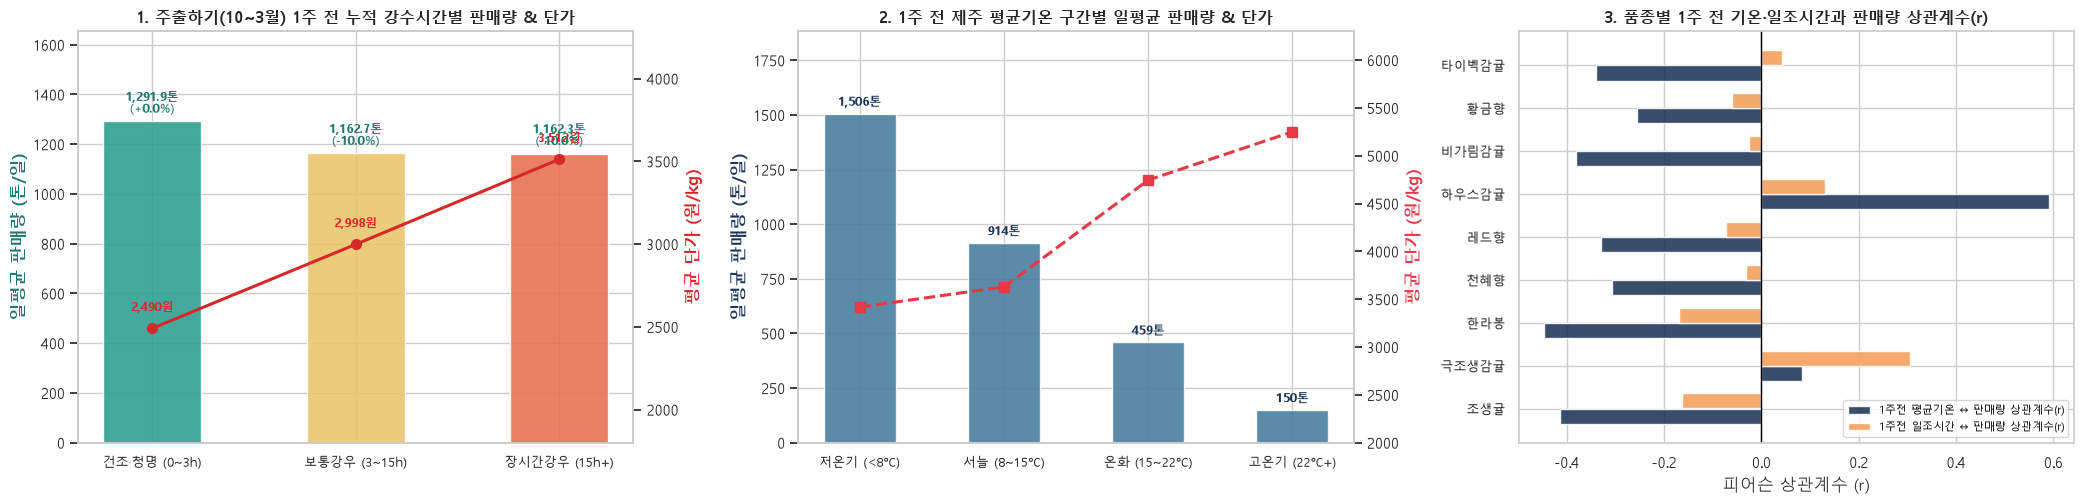

,구분 / 품종명,분석 일수,1주전 거래량(t-7) ↔ 당일물량(r),예년 동시점 거래량 ↔ 당일물량(r),예년 동시점 물량변화량(Δ) ↔ 금년변화량(r),1주전+예년변화량 결합 ↔ 당일물량(r),1주전 단가(t-7) ↔ 당일단가(r),1주전+예년단가변화량 ↔ 당일단가(r)
0,전체 47개 품종·단위 종합,"29,297건",+0.873,+0.883,+0.382 (유의***),+0.891,+0.600,+0.623
1,조생귤,"2,265건",+0.918,+0.941,+0.401 (유의***),+0.931,+0.658,+0.678
2,극조생감귤,835건,+0.883,+0.946,+0.656 (유의***),+0.933,+0.317,+0.358
3,한라봉,"2,968건",+0.771,+0.766,+0.390 (유의***),+0.805,+0.614,+0.631
4,천혜향,"3,238건",+0.804,+0.621,+0.223 (유의***),+0.812,+0.541,+0.566
5,레드향,"2,125건",+0.685,+0.725,+0.321 (유의***),+0.715,+0.487,+0.517
6,하우스감귤,"6,345건",+0.868,+0.907,+0.393 (유의***),+0.888,+0.707,+0.726
7,비가림감귤,"2,081건",+0.860,+0.877,+0.441 (유의***),+0.886,+0.500,+0.509
8,황금향,"1,081건",+0.522,+0.529,+0.373 (유의***),+0.594,+0.280,+0.302
9,타이벡감귤,417건,+0.783,+0.539,+0.405 (유의***),+0.814,+0.696,+0.721


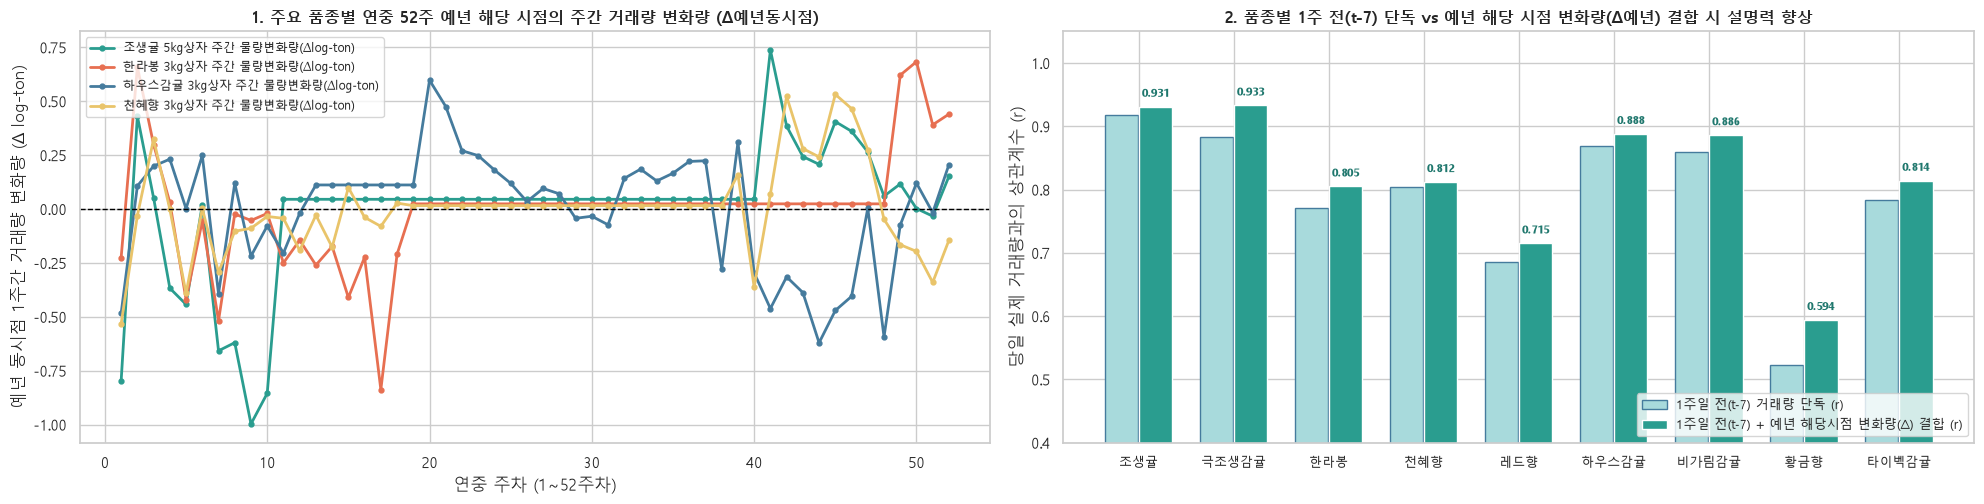

In [3]:
# 1) 날짜별 설날·추석 상대 일수 및 명절 전후(Pre-Surge / Post-Dip) 지수 계산 함수
def compute_holiday_features(date_series):
    unique_dates = pd.Index(date_series.unique()).sort_values()
    h_rows = []
    for d in unique_dates:
        # 가장 가까운 설날 및 추석과의 일수 차이 (d - holiday_date)
        seol_diffs = [(d - s).days for s in SEOLLAL_DATES]
        chu_diffs = [(d - c).days for c in CHUSEOK_DATES]
        d_seol = min(seol_diffs, key=lambda x: abs(x))
        d_chu = min(chu_diffs, key=lambda x: abs(x))

        # 명절 전 16일 ~ 1일 전 대목 가우시안 곡선 (피크: 명절 5~6일 전)
        seol_pre = math.exp(-((d_seol + 5.5) ** 2) / (2 * 4.5 ** 2)) if -18 <= d_seol <= -1 else 0.0
        # 명절 직후 1일 ~ 12일 후 수요 조정 곡선 (피크: 명절 4일 후)
        seol_post = math.exp(-((d_seol - 4.0) ** 2) / (2 * 3.5 ** 2)) if 1 <= d_seol <= 12 else 0.0

        chu_pre = math.exp(-((d_chu + 5.5) ** 2) / (2 * 4.5 ** 2)) if -18 <= d_chu <= -1 else 0.0
        chu_post = math.exp(-((d_chu - 4.0) ** 2) / (2 * 3.5 ** 2)) if 1 <= d_chu <= 12 else 0.0

        # 명절 구간 라벨
        if -14 <= d_seol <= -1:
            h_period = '설날 전(D-14~D-1)'
        elif 1 <= d_seol <= 7:
            h_period = '설날 후(D+1~D+7)'
        elif -14 <= d_chu <= -1:
            h_period = '추석 전(D-14~D-1)'
        elif 1 <= d_chu <= 7:
            h_period = '추석 후(D+1~D+7)'
        else:
            h_period = '평시'

        h_rows.append({
            'date': d,
            'd_seol': d_seol,
            'd_chu': d_chu,
            'seollal_pre_surge': seol_pre,
            'seollal_post_dip': seol_post,
            'chuseok_pre_surge': chu_pre,
            'chuseok_post_dip': chu_post,
            'holiday_period': h_period
        })
    return pd.DataFrame(h_rows)

# 2) 47개 대상 (품종, 거래단위) 필터링 후 날짜별(date) 집계
df_target = df.merge(
    top5_units[['variety', 'box_unit', 'group_id', '단위중량_kg']],
    on=['variety', 'box_unit'],
    how='inner'
)
df_target['vol_teuk'] = np.where(df_target['grade_5'] == '특', df_target['volume_kg'], 0.0)

daily_df = (
    df_target.groupby(['group_id', 'variety', 'box_unit', '단위중량_kg', 'date'], as_index=False)
    .agg(
        tx_count=('trd_clcln_ymd', 'count'),
        volume_kg=('volume_kg', 'sum'),
        total_price=('total_price', 'sum'),
        box_price_mean=('box_price', 'mean'),
        auction_ratio=('is_auction', 'mean'),
        vol_teuk=('vol_teuk', 'sum')
    )
)
daily_df['week_idx'] = np.minimum(52, (daily_df['date'].dt.dayofyear - 1) // 7 + 1)
before_off_cnt = len(daily_df)
daily_df['is_active_season'] = [
    (v, w) in active_season_pairs
    for v, w in zip(daily_df['variety'], daily_df['week_idx'])
]
daily_df = daily_df[daily_df['is_active_season']].sort_values(['group_id', 'date']).reset_index(drop=True)
print(f"품종별 계절적 비수기(Off-Season) 일자 제외 완료: {before_off_cnt:,}건 -> 출하기 유효 일자 {len(daily_df):,}건 (비수기 미미 거래 {before_off_cnt - len(daily_df):,}건 제외)")

daily_df['unit_weight_kg'] = np.where(daily_df['단위중량_kg'] > 0, daily_df['단위중량_kg'], 5.0)
daily_df['volume_ton'] = daily_df['volume_kg'] / 1000.0
daily_df['unit_price_kg'] = daily_df['total_price'] / (daily_df['volume_kg'] + 1e-8)
daily_df['ratio_teuk'] = daily_df['vol_teuk'] / (daily_df['volume_kg'] + 1e-8)

# 설날·추석 명절 파생 피처 결합
holiday_cal_df = compute_holiday_features(daily_df['date'])
daily_df = daily_df.merge(holiday_cal_df, on='date', how='left')

# 주요 품종별 설날·추석 명절 전후 실제 가격 및 거래량 변동 요약표 출력
holiday_impact_rows = []
for v_name in ['한라봉', '레드향', '천혜향', '조생귤', '하우스감귤', '극조생감귤', '비가림감귤', '황금향']:
    sub_v = daily_df[daily_df['variety'] == v_name]
    norm_p = sub_v[sub_v['holiday_period'] == '평시']['unit_price_kg'].median()
    seol_pre_p = sub_v[sub_v['holiday_period'] == '설날 전(D-14~D-1)']['unit_price_kg'].median()
    seol_post_p = sub_v[sub_v['holiday_period'] == '설날 후(D+1~D+7)']['unit_price_kg'].median()
    chu_pre_p = sub_v[sub_v['holiday_period'] == '추석 전(D-14~D-1)']['unit_price_kg'].median()
    chu_post_p = sub_v[sub_v['holiday_period'] == '추석 후(D+1~D+7)']['unit_price_kg'].median()

    holiday_impact_rows.append({
        '품종명': v_name,
        '평시 중앙단가(원/kg)': f"{norm_p:,.0f} 원" if pd.notnull(norm_p) else "-",
        '설날 전(D-14~D-1) 단가': f"{seol_pre_p:,.0f} 원 ({(seol_pre_p/norm_p - 1)*100:+.1f}%)" if pd.notnull(seol_pre_p) and pd.notnull(norm_p) else "-",
        '설날 후(D+1~D+7) 단가': f"{seol_post_p:,.0f} 원 ({(seol_post_p/norm_p - 1)*100:+.1f}%)" if pd.notnull(seol_post_p) and pd.notnull(norm_p) else "-",
        '추석 전(D-14~D-1) 단가': f"{chu_pre_p:,.0f} 원 ({(chu_pre_p/norm_p - 1)*100:+.1f}%)" if pd.notnull(chu_pre_p) and pd.notnull(norm_p) else "-",
        '추석 후(D+1~D+7) 단가': f"{chu_post_p:,.0f} 원 ({(chu_post_p/norm_p - 1)*100:+.1f}%)" if pd.notnull(chu_post_p) and pd.notnull(norm_p) else "-"
    })
print("[주요 품종별 설날·추석 명절 전(D-14~D-1) 및 명절 후(D+1~D+7) 단가 변동 분석]")
display(pd.DataFrame(holiday_impact_rows))

# 2-1) 1주일 전 제주 산지 날씨(forecast.csv) 결합 및 판매량·단가 영향 통계 분석
wx_merge_cols = [
    'date', 'wx_temp_lag7', 'wx_temp_anom_lag7', 'wx_rain_dur_lag7', 'wx_sunshine_lag7', 'wx_snow_lag7',
    'wx_temp_wk1_mean', 'wx_temp_anom_wk1', 'wx_rain_dur_wk1_sum', 'wx_rain_max_wk1',
    'wx_sunshine_wk1_mean', 'wx_snow_wk1_max',
    'wx_temp_wk1_norm', 'wx_temp_anom_norm', 'wx_rain_wk1_norm', 'wx_sun_wk1_norm', 'wx_snow_wk1_norm'
]
daily_df = daily_df.merge(daily_wx[wx_merge_cols], on='date', how='left')
daily_df['wx_rain_regime'] = pd.cut(
    daily_df['wx_rain_dur_wk1_sum'],
    bins=[-1, 3.0, 15.0, 500.0],
    labels=['건조·청명(0~3h)', '보통강우(3~15h)', '장시간강우(15h+)']
).astype(str)

def calc_corr_pval(x, y):
    x_a = np.asarray(x, dtype=float)
    y_a = np.asarray(y, dtype=float)
    m = np.isfinite(x_a) & np.isfinite(y_a)
    if m.sum() < 5:
        return 0.0, 1.0
    r = float(np.corrcoef(x_a[m], y_a[m])[0, 1])
    t_val = abs(r) * math.sqrt((m.sum() - 2) / max(1e-12, 1.0 - r * r))
    p_val = math.erfc(t_val / math.sqrt(2.0))
    return r, p_val

mkt_daily_agg = daily_df.groupby('date', as_index=False).agg(
    vol_ton=('volume_ton', 'sum'),
    total_amt=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum'),
    wx_temp_wk1_mean=('wx_temp_wk1_mean', 'first'),
    wx_sunshine_wk1_mean=('wx_sunshine_wk1_mean', 'first'),
    wx_rain_dur_wk1_sum=('wx_rain_dur_wk1_sum', 'first'),
    wx_snow_wk1_max=('wx_snow_wk1_max', 'first')
)
mkt_daily_agg['prc_kg'] = mkt_daily_agg['total_amt'] / (mkt_daily_agg['total_kg'] + 1e-8)

wx_corr_rows = []
for label, sub_c in [('전체 감귤 시장 합계', mkt_daily_agg)] + [
    (v, daily_df[daily_df['variety'] == v].groupby('date', as_index=False).agg(
        vol_ton=('volume_ton', 'sum'),
        prc_kg=('unit_price_kg', 'median'),
        wx_temp_wk1_mean=('wx_temp_wk1_mean', 'first'),
        wx_sunshine_wk1_mean=('wx_sunshine_wk1_mean', 'first'),
        wx_rain_dur_wk1_sum=('wx_rain_dur_wk1_sum', 'first'),
        wx_snow_wk1_max=('wx_snow_wk1_max', 'first')
    )) for v in ['조생귤', '극조생감귤', '한라봉', '천혜향', '레드향', '하우스감귤', '비가림감귤', '황금향', '타이벡감귤']
]:
    rt, pt = calc_corr_pval(sub_c['wx_temp_wk1_mean'], sub_c['vol_ton'])
    rs, ps = calc_corr_pval(sub_c['wx_sunshine_wk1_mean'], sub_c['vol_ton'])
    rr, pr = calc_corr_pval(sub_c['wx_rain_dur_wk1_sum'], sub_c['vol_ton'])
    rp, pp = calc_corr_pval(sub_c['wx_temp_wk1_mean'], sub_c['prc_kg'])
    wx_corr_rows.append({
        '구분 / 품종명': label,
        '분석 영업일수': f"{len(sub_c):,}일",
        '1주전 평균기온 ↔ 판매량(r)': f"{rt:+.3f} ({'유의***' if pt < 0.001 else ('유의*' if pt < 0.05 else '비유의')})",
        '1주전 일조시간 ↔ 판매량(r)': f"{rs:+.3f} ({'유의***' if ps < 0.001 else ('유의*' if ps < 0.05 else '비유의')})",
        '1주전 누적강수 ↔ 판매량(r)': f"{rr:+.3f} ({'유의***' if pr < 0.001 else ('유의*' if pr < 0.05 else '비유의')})",
        '1주전 평균기온 ↔ 단가(r)': f"{rp:+.3f} ({'유의***' if pp < 0.001 else ('유의*' if pp < 0.05 else '비유의')})",
        '_rt': rt, '_rs': rs, '_rr': rr
    })

wx_corr_df = pd.DataFrame(wx_corr_rows)
print("\n[1주일 전 제주 산지 날씨(forecast.csv)와 일별 판매량(거래량) 및 단가의 상관관계 분석]")
display(wx_corr_df.drop(columns=['_rt', '_rs', '_rr']))

mkt_harvest = mkt_daily_agg[mkt_daily_agg['date'].dt.month.isin([10, 11, 12, 1, 2, 3])].copy()
mkt_harvest['rain_bin'] = pd.cut(mkt_harvest['wx_rain_dur_wk1_sum'], bins=[-1, 3.0, 15.0, 500.0], labels=['건조·청명 (0~3h)', '보통강우 (3~15h)', '장시간강우 (15h+)'])
mkt_daily_agg['temp_bin'] = pd.cut(mkt_daily_agg['wx_temp_wk1_mean'], bins=[-10, 8.0, 15.0, 22.0, 40.0], labels=['저온기 (<8°C)', '서늘 (8~15°C)', '온화 (15~22°C)', '고온기 (22°C+)'])

rain_grp = mkt_harvest.groupby('rain_bin', observed=False).agg(영업일수=('vol_ton', 'count'), 일평균판매량=('vol_ton', 'mean'), 평균단가=('prc_kg', 'mean')).reset_index()
base_r_vol = rain_grp['일평균판매량'].iloc[0]
base_r_prc = rain_grp['평균단가'].iloc[0]
rain_grp['판매량 증감률(건조대비)'] = [f"{(v / base_r_vol - 1)*100:+.1f}%" for v in rain_grp['일평균판매량']]
rain_grp['단가 증감률(건조대비)'] = [f"{(p / base_r_prc - 1)*100:+.1f}%" for p in rain_grp['평균단가']]
rain_grp['일평균판매량(톤/일)'] = rain_grp['일평균판매량'].map('{:,.1f} 톤/일'.format)
rain_grp['평균단가(원/kg)'] = rain_grp['평균단가'].map('{:,.0f} 원/kg'.format)
print("\n[주출하기(10~3월) 1주일 전 누적 강수 계속시간 구간별 일평균 판매량 및 단가 변화 (우천 수확지연 효과)]")
display(rain_grp[['rain_bin', '영업일수', '일평균판매량(톤/일)', '판매량 증감률(건조대비)', '평균단가(원/kg)', '단가 증감률(건조대비)']].rename(columns={'rain_bin': '1주전 누적 강수시간 구간'}))

fig_wx, axes_wx = plt.subplots(1, 3, figsize=(21, 5.2))
x_rb = np.arange(len(rain_grp))
ax_w1 = axes_wx[0]
bars_w1 = ax_w1.bar(x_rb, rain_grp['일평균판매량'], width=0.48, color=['#2A9D8F', '#E9C46A', '#E76F51'], alpha=0.88)
ax_w1.set_title('1. 주출하기(10~3월) 1주 전 누적 강수시간별 판매량 & 단가', fontsize=11.5, fontweight='bold')
ax_w1.set_xticks(x_rb)
ax_w1.set_xticklabels(rain_grp['rain_bin'], fontsize=9.5)
ax_w1.set_ylabel('일평균 판매량 (톤/일)', color='#1F776D', fontweight='bold')
ax_w1.set_ylim(0, rain_grp['일평균판매량'].max() * 1.28)
for bi, b in enumerate(bars_w1):
    ax_w1.text(b.get_x() + b.get_width()/2, b.get_height() + 25, f"{rain_grp['일평균판매량'].iloc[bi]:,.1f}톤\n({rain_grp['판매량 증감률(건조대비)'].iloc[bi]})", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1F776D')
ax_w1_r = ax_w1.twinx()
ax_w1_r.plot(x_rb, rain_grp['평균단가'], color='#D62828', marker='o', linewidth=2.2, markersize=7)
ax_w1_r.set_ylabel('평균 단가 (원/kg)', color='#D62828', fontweight='bold')
ax_w1_r.set_ylim(1800, rain_grp['평균단가'].max() * 1.22)
ax_w1_r.grid(False)
for xi, pv in enumerate(rain_grp['평균단가']):
    ax_w1_r.text(xi, pv + 90, f"{pv:,.0f}원", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#D62828')

temp_grp = mkt_daily_agg.groupby('temp_bin', observed=False).agg(일평균판매량=('vol_ton', 'mean'), 평균단가=('prc_kg', 'mean')).reset_index()
x_tb = np.arange(len(temp_grp))
ax_w2 = axes_wx[1]
bars_w2 = ax_w2.bar(x_tb, temp_grp['일평균판매량'], width=0.5, color='#457B9D', alpha=0.88)
ax_w2.set_title('2. 1주 전 제주 평균기온 구간별 일평균 판매량 & 단가', fontsize=11.5, fontweight='bold')
ax_w2.set_xticks(x_tb)
ax_w2.set_xticklabels(temp_grp['temp_bin'], fontsize=9.5)
ax_w2.set_ylabel('일평균 판매량 (톤/일)', color='#1D3557', fontweight='bold')
ax_w2.set_ylim(0, temp_grp['일평균판매량'].max() * 1.25)
for bi, b in enumerate(bars_w2):
    ax_w2.text(b.get_x() + b.get_width()/2, b.get_height() + 25, f"{temp_grp['일평균판매량'].iloc[bi]:,.0f}톤", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1D3557')
ax_w2_r = ax_w2.twinx()
ax_w2_r.plot(x_tb, temp_grp['평균단가'], color='#E63946', marker='s', linestyle='--', linewidth=2.2, markersize=6.5)
ax_w2_r.set_ylabel('평균 단가 (원/kg)', color='#E63946', fontweight='bold')
ax_w2_r.set_ylim(2000, temp_grp['평균단가'].max() * 1.2)
ax_w2_r.grid(False)

sub_vc = wx_corr_df.iloc[1:].copy()
y_vc = np.arange(len(sub_vc))
ax_w3 = axes_wx[2]
ax_w3.barh(y_vc - 0.18, sub_vc['_rt'], height=0.35, color='#1D3557', alpha=0.88, label='1주전 평균기온 ↔ 판매량 상관계수(r)')
ax_w3.barh(y_vc + 0.18, sub_vc['_rs'], height=0.35, color='#F4A261', alpha=0.92, label='1주전 일조시간 ↔ 판매량 상관계수(r)')
ax_w3.axvline(0, color='black', linewidth=1.0)
ax_w3.set_yticks(y_vc)
ax_w3.set_yticklabels(sub_vc['구분 / 품종명'], fontsize=9)
ax_w3.set_xlabel('피어슨 상관계수 (r)')
ax_w3.set_title('3. 품종별 1주 전 기온·일조시간과 판매량 상관계수(r)', fontsize=11.5, fontweight='bold')
ax_w3.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

# 3) 날짜 캘린더 및 그룹별 계절성·명절·기상 민감도 프로파일 산출
daily_df['year'] = daily_df['date'].dt.year
daily_df['month'] = daily_df['date'].dt.month
daily_df['day'] = daily_df['date'].dt.day
daily_df['dayofweek'] = daily_df['date'].dt.dayofweek
daily_df['dayofyear'] = daily_df['date'].dt.dayofyear
daily_df['time_idx'] = (daily_df['date'] - daily_df['date'].min()).dt.days

tr_mask = daily_df['year'] <= 2025
grp_prof = (
    daily_df[tr_mask]
    .groupby('group_id', as_index=False)
    .agg(
        grp_vol_mean=('volume_ton', 'mean'),
        grp_prc_mean=('unit_price_kg', 'median'),
        grp_prc_std=('unit_price_kg', 'std'),
        grp_teuk_mean=('ratio_teuk', 'mean')
    )
)
grp_prof['grp_prc_std'] = grp_prof['grp_prc_std'].fillna(400.0).clip(lower=150.0, upper=1500.0)

grp_month_prof = (
    daily_df[tr_mask]
    .groupby(['group_id', 'month'], as_index=False)
    .agg(
        seasonal_vol_mean=('volume_ton', 'mean'),
        seasonal_prc_mean=('unit_price_kg', 'median')
    )
)

# 그룹별 명절 구간(설전/설후/추석전/추석후/평시) 기대 단가 편차 및 물량 배율 프로파일
grp_hol_prof = (
    daily_df[tr_mask]
    .groupby(['group_id', 'holiday_period'], as_index=False)
    .agg(
        hol_prc_median=('unit_price_kg', 'median'),
        hol_vol_mean=('volume_ton', 'mean')
    )
)

# 그룹·월별 1주 전 강수 구간(건조/보통강우/장시간강우) 순수 기상 물량 및 단가 효과 프로파일
grp_wx_prof = (
    daily_df[tr_mask]
    .groupby(['group_id', 'month', 'wx_rain_regime'], as_index=False)
    .agg(
        wx_prc_median=('unit_price_kg', 'median'),
        wx_vol_mean=('volume_ton', 'mean')
    )
)

daily_df = daily_df.merge(grp_prof, on='group_id', how='left')
daily_df = daily_df.merge(grp_month_prof, on=['group_id', 'month'], how='left')
daily_df = daily_df.merge(grp_hol_prof, on=['group_id', 'holiday_period'], how='left')
daily_df = daily_df.merge(grp_wx_prof, on=['group_id', 'month', 'wx_rain_regime'], how='left')

daily_df['seasonal_vol_mean'] = daily_df['seasonal_vol_mean'].fillna(daily_df['grp_vol_mean'])
daily_df['seasonal_prc_mean'] = daily_df['seasonal_prc_mean'].fillna(daily_df['grp_prc_mean'])
daily_df['hol_prc_median'] = daily_df['hol_prc_median'].fillna(daily_df['seasonal_prc_mean'])
daily_df['hol_vol_mean'] = daily_df['hol_vol_mean'].fillna(daily_df['seasonal_vol_mean'])
daily_df['wx_prc_median'] = daily_df['wx_prc_median'].fillna(daily_df['seasonal_prc_mean'])
daily_df['wx_vol_mean'] = daily_df['wx_vol_mean'].fillna(daily_df['seasonal_vol_mean'])

# 명절 전후 가격 기대 효과(Z-score) 및 물량 기대 효과(log-ratio)
daily_df['holiday_prc_effect'] = (
    (daily_df['hol_prc_median'] - daily_df['seasonal_prc_mean']) / daily_df['grp_prc_std']
).clip(-1.5, 1.5)
daily_df['holiday_vol_effect'] = (
    np.log1p(daily_df['hol_vol_mean']) - np.log1p(daily_df['seasonal_vol_mean'])
).clip(-1.5, 1.5)

# 1주일 전 날씨(우천 수확지연·기온)에 따른 품종·단위별 기대 물량 및 단가 효과
daily_df['wx_prc_effect'] = (
    (daily_df['wx_prc_median'] - daily_df['seasonal_prc_mean']) / daily_df['grp_prc_std']
).clip(-1.5, 1.5)
daily_df['wx_vol_effect'] = (
    np.log1p(daily_df['wx_vol_mean']) - np.log1p(daily_df['seasonal_vol_mean'])
).clip(-1.5, 1.5)

# 일별 단가 극단 노이즈 완충
daily_df['unit_price_kg_clean'] = np.clip(
    daily_df['unit_price_kg'],
    daily_df['grp_prc_mean'] - 2.5 * daily_df['grp_prc_std'],
    daily_df['grp_prc_mean'] + 2.5 * daily_df['grp_prc_std']
).clip(lower=400.0)

# 4) Known Future 주기 함수 및 Historical Daily Lags (t-1, t-2, t-3, t-7, t-14, t-30) 생성
daily_df['sin_doy1'] = np.sin(2 * np.pi * daily_df['dayofyear'] / 365.25)
daily_df['cos_doy1'] = np.cos(2 * np.pi * daily_df['dayofyear'] / 365.25)
daily_df['sin_doy2'] = np.sin(4 * np.pi * daily_df['dayofyear'] / 365.25)
daily_df['cos_doy2'] = np.cos(4 * np.pi * daily_df['dayofyear'] / 365.25)
daily_df['sin_dow'] = np.sin(2 * np.pi * daily_df['dayofweek'] / 6.0)  # 월(0)~토(5) 6일 경매 주기
daily_df['cos_dow'] = np.cos(2 * np.pi * daily_df['dayofweek'] / 6.0)
daily_df['year_norm'] = (daily_df['year'] - 2021) / 5.0

daily_df['log_vol'] = np.log1p(daily_df['volume_ton'])
daily_df['seasonal_log_vol'] = np.log1p(daily_df['seasonal_vol_mean'])
daily_df['log_grp_vol_mean'] = np.log1p(daily_df['grp_vol_mean'])
daily_df['norm_grp_prc_mean'] = daily_df['grp_prc_mean'] / 5000.0
daily_df['norm_unit_weight'] = daily_df['unit_weight_kg'] / 10.0
daily_df['norm_seasonal_prc'] = (daily_df['seasonal_prc_mean'] - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']

daily_lags = [1, 2, 3, 7, 14, 30]
for lag in daily_lags:
    daily_df[f'log_vol_lag_{lag}'] = (
        daily_df.groupby('group_id')['log_vol'].shift(lag)
        .fillna(daily_df['seasonal_log_vol'])
    )
    prc_s = (
        daily_df.groupby('group_id')['unit_price_kg_clean'].shift(lag)
        .fillna(daily_df['seasonal_prc_mean'])
    )
    daily_df[f'norm_prc_lag_{lag}'] = (prc_s - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']

daily_df['vol_roll7_mean'] = (
    daily_df.groupby('group_id')['log_vol']
    .transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
    .fillna(daily_df['seasonal_log_vol'])
)
daily_df['vol_roll14_mean'] = (
    daily_df.groupby('group_id')['log_vol']
    .transform(lambda s: s.shift(1).rolling(14, min_periods=1).mean())
    .fillna(daily_df['seasonal_log_vol'])
)

prc_r7 = (
    daily_df.groupby('group_id')['unit_price_kg_clean']
    .transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
    .fillna(daily_df['seasonal_prc_mean'])
)
prc_r14 = (
    daily_df.groupby('group_id')['unit_price_kg_clean']
    .transform(lambda s: s.shift(1).rolling(14, min_periods=1).mean())
    .fillna(daily_df['seasonal_prc_mean'])
)
daily_df['norm_prc_roll7'] = (prc_r7 - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']
daily_df['norm_prc_roll14'] = (prc_r14 - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']
daily_df['ratio_teuk_lag1'] = daily_df.groupby('group_id')['ratio_teuk'].shift(1).fillna(daily_df['grp_teuk_mean'])

daily_df['target_vol_log'] = daily_df['log_vol']
daily_df['target_prc_norm'] = (daily_df['unit_price_kg_clean'] - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']


# 5) 1년 단위 거래량·단가 변화에 따른 '1주일 전(t-7) 가격·거래량 및 변화량'과 '예년 해당 시점의 가격·거래량 및 변화량(Δ예년동시점)' 구축
daily_df['norm_prc_clean'] = (daily_df['unit_price_kg_clean'] - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']

hist_wk_prof = (
    daily_df[tr_mask]
    .groupby(['group_id', 'week_idx'], as_index=False)
    .agg(
        hist_wk_vol_ton=('volume_ton', 'mean'),
        hist_wk_log_vol=('log_vol', 'mean'),
        hist_wk_prc_kg=('unit_price_kg_clean', 'median'),
        hist_wk_norm_prc=('norm_prc_clean', 'mean')
    )
)

gids = daily_df['group_id'].unique()
wk_full_grid = pd.MultiIndex.from_product([gids, range(1, 53)], names=['group_id', 'week_idx']).to_frame().reset_index(drop=True)
grp_base = daily_df[['group_id', 'grp_vol_mean', 'grp_prc_mean', 'grp_prc_std', 'log_grp_vol_mean']].drop_duplicates('group_id')
wk_full_grid = wk_full_grid.merge(grp_base, on='group_id', how='left').merge(hist_wk_prof, on=['group_id', 'week_idx'], how='left')

wk_full_grid['hist_wk_log_vol'] = wk_full_grid.groupby('group_id')['hist_wk_log_vol'].transform(
    lambda s: s.interpolate(limit_direction='both')
).fillna(wk_full_grid['log_grp_vol_mean'])
wk_full_grid['hist_wk_vol_ton'] = wk_full_grid['hist_wk_vol_ton'].fillna(np.expm1(wk_full_grid['hist_wk_log_vol']))
wk_full_grid['hist_wk_norm_prc'] = wk_full_grid.groupby('group_id')['hist_wk_norm_prc'].transform(
    lambda s: s.interpolate(limit_direction='both')
).fillna(0.0)
wk_full_grid['hist_wk_prc_kg'] = wk_full_grid['hist_wk_prc_kg'].fillna(
    wk_full_grid['grp_prc_mean'] + wk_full_grid['hist_wk_norm_prc'] * wk_full_grid['grp_prc_std']
)

wk_full_grid['prev_week_idx'] = (wk_full_grid['week_idx'] - 2) % 52 + 1
wk_full_grid = wk_full_grid.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_log_vol', 'hist_wk_norm_prc', 'hist_wk_vol_ton', 'hist_wk_prc_kg']].rename(
        columns={
            'week_idx': 'prev_week_idx',
            'hist_wk_log_vol': 'hist_prev_wk_log_vol',
            'hist_wk_norm_prc': 'hist_prev_wk_norm_prc',
            'hist_wk_vol_ton': 'hist_prev_wk_vol_ton',
            'hist_wk_prc_kg': 'hist_prev_wk_prc_kg'
        }
    ),
    on=['group_id', 'prev_week_idx'],
    how='left'
)
wk_full_grid['hist_wk_vol_diff'] = (wk_full_grid['hist_wk_log_vol'] - wk_full_grid['hist_prev_wk_log_vol']).clip(-2.0, 2.0)
wk_full_grid['hist_wk_prc_diff'] = (wk_full_grid['hist_wk_norm_prc'] - wk_full_grid['hist_prev_wk_norm_prc']).clip(-2.0, 2.0)

yr_wk_actual = (
    daily_df.groupby(['group_id', 'year', 'week_idx'], as_index=False)
    .agg(
        yr_wk_vol_ton=('volume_ton', 'mean'),
        yr_wk_log_vol=('log_vol', 'mean'),
        yr_wk_prc_kg=('unit_price_kg_clean', 'median'),
        yr_wk_norm_prc=('norm_prc_clean', 'mean')
    )
)

all_years = list(range(2021, 2028))
yr_wk_grid = pd.MultiIndex.from_product([gids, all_years, range(1, 53)], names=['group_id', 'year', 'week_idx']).to_frame().reset_index(drop=True)
yr_wk_grid = yr_wk_grid.merge(yr_wk_actual, on=['group_id', 'year', 'week_idx'], how='left')
yr_wk_grid = yr_wk_grid.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_log_vol', 'hist_wk_prc_kg', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']],
    on=['group_id', 'week_idx'],
    how='left'
)
yr_wk_grid['yr_wk_vol_ton'] = yr_wk_grid['yr_wk_vol_ton'].fillna(yr_wk_grid['hist_wk_vol_ton'])
yr_wk_grid['yr_wk_log_vol'] = yr_wk_grid['yr_wk_log_vol'].fillna(yr_wk_grid['hist_wk_log_vol'])
yr_wk_grid['yr_wk_prc_kg'] = yr_wk_grid['yr_wk_prc_kg'].fillna(yr_wk_grid['hist_wk_prc_kg'])
yr_wk_grid['yr_wk_norm_prc'] = yr_wk_grid['yr_wk_norm_prc'].fillna(yr_wk_grid['hist_wk_norm_prc'])

yr_wk_grid = yr_wk_grid.sort_values(['group_id', 'year', 'week_idx']).reset_index(drop=True)
yr_wk_grid['yr_wk_vol_diff_1w'] = yr_wk_grid.groupby('group_id')['yr_wk_log_vol'].diff(1).fillna(yr_wk_grid['hist_wk_vol_diff']).clip(-2.0, 2.0)
yr_wk_grid['yr_wk_prc_diff_1w'] = yr_wk_grid.groupby('group_id')['yr_wk_norm_prc'].diff(1).fillna(yr_wk_grid['hist_wk_prc_diff']).clip(-2.0, 2.0)

prev_yr_lookup = yr_wk_grid[['group_id', 'year', 'week_idx', 'yr_wk_vol_ton', 'yr_wk_log_vol', 'yr_wk_prc_kg', 'yr_wk_norm_prc', 'yr_wk_vol_diff_1w', 'yr_wk_prc_diff_1w']].copy()
prev_yr_lookup['target_year'] = prev_yr_lookup['year'] + 1
prev_yr_lookup = prev_yr_lookup.drop(columns=['year']).rename(columns={
    'target_year': 'year',
    'yr_wk_vol_ton': 'prev_yr_vol_ton',
    'yr_wk_log_vol': 'prev_yr_log_vol',
    'yr_wk_prc_kg': 'prev_yr_prc_kg',
    'yr_wk_norm_prc': 'prev_yr_norm_prc',
    'yr_wk_vol_diff_1w': 'prev_yr_vol_wk_diff',
    'yr_wk_prc_diff_1w': 'prev_yr_prc_wk_diff'
})

daily_df = daily_df.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_log_vol', 'hist_wk_prc_kg', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']],
    on=['group_id', 'week_idx'],
    how='left'
)
daily_df = daily_df.merge(prev_yr_lookup, on=['group_id', 'year', 'week_idx'], how='left')

daily_df['prev_yr_vol_ton'] = daily_df['prev_yr_vol_ton'].fillna(daily_df['hist_wk_vol_ton'])
daily_df['prev_yr_log_vol'] = daily_df['prev_yr_log_vol'].fillna(daily_df['hist_wk_log_vol'])
daily_df['prev_yr_prc_kg'] = daily_df['prev_yr_prc_kg'].fillna(daily_df['hist_wk_prc_kg'])
daily_df['prev_yr_norm_prc'] = daily_df['prev_yr_norm_prc'].fillna(daily_df['hist_wk_norm_prc'])
daily_df['prev_yr_vol_wk_diff'] = daily_df['prev_yr_vol_wk_diff'].fillna(daily_df['hist_wk_vol_diff'])
daily_df['prev_yr_prc_wk_diff'] = daily_df['prev_yr_prc_wk_diff'].fillna(daily_df['hist_wk_prc_diff'])

daily_df['yoy_same_period_log_vol'] = 0.50 * daily_df['prev_yr_log_vol'] + 0.50 * daily_df['hist_wk_log_vol']
daily_df['yoy_same_period_norm_prc'] = 0.35 * daily_df['prev_yr_norm_prc'] + 0.65 * daily_df['hist_wk_norm_prc']
daily_df['yoy_same_period_vol_diff'] = 0.30 * daily_df['prev_yr_vol_wk_diff'] + 0.70 * daily_df['hist_wk_vol_diff']
daily_df['yoy_same_period_prc_diff'] = 0.30 * daily_df['prev_yr_prc_wk_diff'] + 0.70 * daily_df['hist_wk_prc_diff']

daily_df['vol_diff_1w'] = (daily_df['log_vol_lag_1'] - daily_df['log_vol_lag_7']).clip(-2.5, 2.5)
daily_df['prc_diff_1w'] = (daily_df['norm_prc_lag_1'] - daily_df['norm_prc_lag_7']).clip(-2.5, 2.5)
daily_df['vol_yoy_change'] = (daily_df['vol_roll7_mean'] - daily_df['yoy_same_period_log_vol']).clip(-2.5, 2.5)
daily_df['prc_yoy_change'] = (daily_df['norm_prc_roll7'] - daily_df['yoy_same_period_norm_prc']).clip(-2.5, 2.5)

daily_df['exp_vol_yoy_chg'] = (daily_df['log_vol_lag_7'] + daily_df['yoy_same_period_vol_diff']).clip(lower=0.0)
daily_df['exp_prc_yoy_chg'] = (daily_df['norm_prc_lag_7'] + daily_df['yoy_same_period_prc_diff']).clip(-3.0, 3.0)

yoy_prof_df = yr_wk_grid[['group_id', 'year', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_prc_kg', 'hist_wk_log_vol', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']].merge(
    prev_yr_lookup, on=['group_id', 'year', 'week_idx'], how='left'
)
yoy_prof_df['prev_yr_log_vol'] = yoy_prof_df['prev_yr_log_vol'].fillna(yoy_prof_df['hist_wk_log_vol'])
yoy_prof_df['prev_yr_norm_prc'] = yoy_prof_df['prev_yr_norm_prc'].fillna(yoy_prof_df['hist_wk_norm_prc'])
yoy_prof_df['prev_yr_vol_wk_diff'] = yoy_prof_df['prev_yr_vol_wk_diff'].fillna(yoy_prof_df['hist_wk_vol_diff'])
yoy_prof_df['prev_yr_prc_wk_diff'] = yoy_prof_df['prev_yr_prc_wk_diff'].fillna(yoy_prof_df['hist_wk_prc_diff'])
yoy_prof_df['yoy_same_period_log_vol'] = 0.50 * yoy_prof_df['prev_yr_log_vol'] + 0.50 * yoy_prof_df['hist_wk_log_vol']
yoy_prof_df['yoy_same_period_norm_prc'] = 0.35 * yoy_prof_df['prev_yr_norm_prc'] + 0.65 * yoy_prof_df['hist_wk_norm_prc']
yoy_prof_df['yoy_same_period_vol_diff'] = 0.30 * yoy_prof_df['prev_yr_vol_wk_diff'] + 0.70 * yoy_prof_df['hist_wk_vol_diff']
yoy_prof_df['yoy_same_period_prc_diff'] = 0.30 * yoy_prof_df['prev_yr_prc_wk_diff'] + 0.70 * yoy_prof_df['hist_wk_prc_diff']
yoy_lookup_dict = yoy_prof_df.set_index(['group_id', 'year', 'week_idx'])[
    ['hist_wk_vol_ton', 'hist_wk_prc_kg', 'yoy_same_period_log_vol', 'yoy_same_period_norm_prc', 'yoy_same_period_vol_diff', 'yoy_same_period_prc_diff']
].to_dict(orient='index')

yoy_corr_rows = []
for v_label, sub_df in [('전체 47개 품종·단위 종합', daily_df)] + [
    (v, daily_df[daily_df['variety'] == v])
    for v in ['조생귤', '극조생감귤', '한라봉', '천혜향', '레드향', '하우스감귤', '비가림감귤', '황금향', '타이벡감귤']
]:
    r_v7, _ = calc_corr_pval(sub_df['log_vol_lag_7'], sub_df['target_vol_log'])
    r_vyoy, _ = calc_corr_pval(sub_df['yoy_same_period_log_vol'], sub_df['target_vol_log'])
    r_vdiff, p_vd = calc_corr_pval(sub_df['yoy_same_period_vol_diff'], sub_df['target_vol_log'] - sub_df['log_vol_lag_7'])
    r_vexp, _ = calc_corr_pval(sub_df['exp_vol_yoy_chg'], sub_df['target_vol_log'])
    r_p7, _ = calc_corr_pval(sub_df['norm_prc_lag_7'], sub_df['target_prc_norm'])
    r_pexp, _ = calc_corr_pval(sub_df['exp_prc_yoy_chg'], sub_df['target_prc_norm'])
    yoy_corr_rows.append({
        '구분 / 품종명': v_label,
        '분석 일수': f"{len(sub_df):,}건",
        '1주전 거래량(t-7) ↔ 당일물량(r)': f"{r_v7:+.3f}",
        '예년 동시점 거래량 ↔ 당일물량(r)': f"{r_vyoy:+.3f}",
        '예년 동시점 물량변화량(Δ) ↔ 금년변화량(r)': f"{r_vdiff:+.3f} ({'유의***' if p_vd < 0.001 else ('유의*' if p_vd < 0.05 else '비유의')})",
        '1주전+예년변화량 결합 ↔ 당일물량(r)': f"{r_vexp:+.3f}",
        '1주전 단가(t-7) ↔ 당일단가(r)': f"{r_p7:+.3f}",
        '1주전+예년단가변화량 ↔ 당일단가(r)': f"{r_pexp:+.3f}"
    })
yoy_corr_summary_df = pd.DataFrame(yoy_corr_rows)
print("\n[품종별 1주일 전(t-7) 가격·거래량 및 예년 해당 시점의 가격·거래량 변화량(Δ예년동시점) 상관관계 분석]")
display(yoy_corr_summary_df)

fig_yoy, axes_yoy = plt.subplots(1, 2, figsize=(20, 5.2))
ax_y1 = axes_yoy[0]
for v_c, col_c in [('조생귤_5kg상자', '#2A9D8F'), ('한라봉_3kg상자', '#E76F51'), ('하우스감귤_3kg상자', '#457B9D'), ('천혜향_3kg상자', '#E9C46A')]:
    sub_wk = wk_full_grid[wk_full_grid['group_id'] == v_c].sort_values('week_idx')
    ax_y1.plot(sub_wk['week_idx'], sub_wk['hist_wk_vol_diff'], marker='o', markersize=3.5, linewidth=2.0, label=f"{v_c.replace('_', ' ')} 주간 물량변화량(Δlog-ton)", color=col_c)
ax_y1.axhline(0, color='black', linestyle='--', linewidth=1.0)
ax_y1.set_title('1. 주요 품종별 연중 52주 예년 해당 시점의 주간 거래량 변화량 (Δ예년동시점)', fontsize=11.5, fontweight='bold')
ax_y1.set_xlabel('연중 주차 (1~52주차)')
ax_y1.set_ylabel('예년 동시점 1주간 거래량 변화량 (Δ log-ton)')
ax_y1.legend(loc='upper left', fontsize=8.5)

ax_y2 = axes_yoy[1]
yoy_plot_sub = yoy_corr_summary_df.iloc[1:].copy()
x_yp = np.arange(len(yoy_plot_sub))
r_1w_vals = [float(s.replace('+', '')) for s in yoy_plot_sub['1주전 거래량(t-7) ↔ 당일물량(r)']]
r_comb_vals = [float(s.replace('+', '')) for s in yoy_plot_sub['1주전+예년변화량 결합 ↔ 당일물량(r)']]
ax_y2.bar(x_yp - 0.18, r_1w_vals, width=0.35, color='#A8DADC', edgecolor='#457B9D', label='1주일 전(t-7) 거래량 단독 (r)')
ax_y2.bar(x_yp + 0.18, r_comb_vals, width=0.35, color='#2A9D8F', label='1주일 전(t-7) + 예년 해당시점 변화량(Δ) 결합 (r)')
for xi, (v1, v2) in enumerate(zip(r_1w_vals, r_comb_vals)):
    ax_y2.text(xi + 0.18, v2 + 0.012, f"{v2:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F776D')
ax_y2.set_xticks(x_yp)
ax_y2.set_xticklabels(yoy_plot_sub['구분 / 품종명'], fontsize=9.5)
ax_y2.set_ylim(0.4, 1.05)
ax_y2.set_ylabel('당일 실제 거래량과의 상관계수 (r)')
ax_y2.set_title('2. 품종별 1주 전(t-7) 단독 vs 예년 해당 시점 변화량(Δ예년) 결합 시 설명력 향상', fontsize=11.5, fontweight='bold')
ax_y2.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"\n설날·추석 명절, 1주전 날씨, 1주전 및 예년 해당 시점 가격·거래량 변화량 포함 날짜별(Daily) 데이터셋 구축 완료: 총 {len(daily_df):,} 개 일자별 샘플 (입력 피처 33종, 시차 8종)")
# 5) 1년 단위 거래량·단가 변화에 따른 '1주일 전(t-7) 가격·거래량 및 변화량'과 '예년 해당 시점의 가격·거래량 및 변화량(Δ예년동시점)' 구축
daily_df['norm_prc_clean'] = (daily_df['unit_price_kg_clean'] - daily_df['grp_prc_mean']) / daily_df['grp_prc_std']

hist_wk_prof = (
    daily_df[tr_mask]
    .groupby(['group_id', 'week_idx'], as_index=False)
    .agg(
        hist_wk_vol_ton=('volume_ton', 'mean'),
        hist_wk_log_vol=('log_vol', 'mean'),
        hist_wk_prc_kg=('unit_price_kg_clean', 'median'),
        hist_wk_norm_prc=('norm_prc_clean', 'mean')
    )
)

gids = daily_df['group_id'].unique()
wk_full_grid = pd.MultiIndex.from_product([gids, range(1, 53)], names=['group_id', 'week_idx']).to_frame().reset_index(drop=True)
grp_base = daily_df[['group_id', 'grp_vol_mean', 'grp_prc_mean', 'grp_prc_std', 'log_grp_vol_mean']].drop_duplicates('group_id')
wk_full_grid = wk_full_grid.merge(grp_base, on='group_id', how='left').merge(hist_wk_prof, on=['group_id', 'week_idx'], how='left')

wk_full_grid['hist_wk_log_vol'] = wk_full_grid.groupby('group_id')['hist_wk_log_vol'].transform(
    lambda s: s.interpolate(limit_direction='both')
).fillna(wk_full_grid['log_grp_vol_mean'])
wk_full_grid['hist_wk_vol_ton'] = wk_full_grid['hist_wk_vol_ton'].fillna(np.expm1(wk_full_grid['hist_wk_log_vol']))
wk_full_grid['hist_wk_norm_prc'] = wk_full_grid.groupby('group_id')['hist_wk_norm_prc'].transform(
    lambda s: s.interpolate(limit_direction='both')
).fillna(0.0)
wk_full_grid['hist_wk_prc_kg'] = wk_full_grid['hist_wk_prc_kg'].fillna(
    wk_full_grid['grp_prc_mean'] + wk_full_grid['hist_wk_norm_prc'] * wk_full_grid['grp_prc_std']
)

wk_full_grid['prev_week_idx'] = (wk_full_grid['week_idx'] - 2) % 52 + 1
wk_full_grid = wk_full_grid.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_log_vol', 'hist_wk_norm_prc', 'hist_wk_vol_ton', 'hist_wk_prc_kg']].rename(
        columns={
            'week_idx': 'prev_week_idx',
            'hist_wk_log_vol': 'hist_prev_wk_log_vol',
            'hist_wk_norm_prc': 'hist_prev_wk_norm_prc',
            'hist_wk_vol_ton': 'hist_prev_wk_vol_ton',
            'hist_wk_prc_kg': 'hist_prev_wk_prc_kg'
        }
    ),
    on=['group_id', 'prev_week_idx'],
    how='left'
)
wk_full_grid['hist_wk_vol_diff'] = (wk_full_grid['hist_wk_log_vol'] - wk_full_grid['hist_prev_wk_log_vol']).clip(-2.0, 2.0)
wk_full_grid['hist_wk_prc_diff'] = (wk_full_grid['hist_wk_norm_prc'] - wk_full_grid['hist_prev_wk_norm_prc']).clip(-2.0, 2.0)

yr_wk_actual = (
    daily_df.groupby(['group_id', 'year', 'week_idx'], as_index=False)
    .agg(
        yr_wk_vol_ton=('volume_ton', 'mean'),
        yr_wk_log_vol=('log_vol', 'mean'),
        yr_wk_prc_kg=('unit_price_kg_clean', 'median'),
        yr_wk_norm_prc=('norm_prc_clean', 'mean')
    )
)

all_years = list(range(2021, 2028))
yr_wk_grid = pd.MultiIndex.from_product([gids, all_years, range(1, 53)], names=['group_id', 'year', 'week_idx']).to_frame().reset_index(drop=True)
yr_wk_grid = yr_wk_grid.merge(yr_wk_actual, on=['group_id', 'year', 'week_idx'], how='left')
yr_wk_grid = yr_wk_grid.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_log_vol', 'hist_wk_prc_kg', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']],
    on=['group_id', 'week_idx'],
    how='left'
)
yr_wk_grid['yr_wk_vol_ton'] = yr_wk_grid['yr_wk_vol_ton'].fillna(yr_wk_grid['hist_wk_vol_ton'])
yr_wk_grid['yr_wk_log_vol'] = yr_wk_grid['yr_wk_log_vol'].fillna(yr_wk_grid['hist_wk_log_vol'])
yr_wk_grid['yr_wk_prc_kg'] = yr_wk_grid['yr_wk_prc_kg'].fillna(yr_wk_grid['hist_wk_prc_kg'])
yr_wk_grid['yr_wk_norm_prc'] = yr_wk_grid['yr_wk_norm_prc'].fillna(yr_wk_grid['hist_wk_norm_prc'])

yr_wk_grid = yr_wk_grid.sort_values(['group_id', 'year', 'week_idx']).reset_index(drop=True)
yr_wk_grid['yr_wk_vol_diff_1w'] = yr_wk_grid.groupby('group_id')['yr_wk_log_vol'].diff(1).fillna(yr_wk_grid['hist_wk_vol_diff']).clip(-2.0, 2.0)
yr_wk_grid['yr_wk_prc_diff_1w'] = yr_wk_grid.groupby('group_id')['yr_wk_norm_prc'].diff(1).fillna(yr_wk_grid['hist_wk_prc_diff']).clip(-2.0, 2.0)

prev_yr_lookup = yr_wk_grid[['group_id', 'year', 'week_idx', 'yr_wk_vol_ton', 'yr_wk_log_vol', 'yr_wk_prc_kg', 'yr_wk_norm_prc', 'yr_wk_vol_diff_1w', 'yr_wk_prc_diff_1w']].copy()
prev_yr_lookup['target_year'] = prev_yr_lookup['year'] + 1
prev_yr_lookup = prev_yr_lookup.drop(columns=['year']).rename(columns={
    'target_year': 'year',
    'yr_wk_vol_ton': 'prev_yr_vol_ton',
    'yr_wk_log_vol': 'prev_yr_log_vol',
    'yr_wk_prc_kg': 'prev_yr_prc_kg',
    'yr_wk_norm_prc': 'prev_yr_norm_prc',
    'yr_wk_vol_diff_1w': 'prev_yr_vol_wk_diff',
    'yr_wk_prc_diff_1w': 'prev_yr_prc_wk_diff'
})

daily_df = daily_df.merge(
    wk_full_grid[['group_id', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_log_vol', 'hist_wk_prc_kg', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']],
    on=['group_id', 'week_idx'],
    how='left'
)
daily_df = daily_df.merge(prev_yr_lookup, on=['group_id', 'year', 'week_idx'], how='left')

daily_df['prev_yr_vol_ton'] = daily_df['prev_yr_vol_ton'].fillna(daily_df['hist_wk_vol_ton'])
daily_df['prev_yr_log_vol'] = daily_df['prev_yr_log_vol'].fillna(daily_df['hist_wk_log_vol'])
daily_df['prev_yr_prc_kg'] = daily_df['prev_yr_prc_kg'].fillna(daily_df['hist_wk_prc_kg'])
daily_df['prev_yr_norm_prc'] = daily_df['prev_yr_norm_prc'].fillna(daily_df['hist_wk_norm_prc'])
daily_df['prev_yr_vol_wk_diff'] = daily_df['prev_yr_vol_wk_diff'].fillna(daily_df['hist_wk_vol_diff'])
daily_df['prev_yr_prc_wk_diff'] = daily_df['prev_yr_prc_wk_diff'].fillna(daily_df['hist_wk_prc_diff'])

daily_df['yoy_same_period_log_vol'] = 0.50 * daily_df['prev_yr_log_vol'] + 0.50 * daily_df['hist_wk_log_vol']
daily_df['yoy_same_period_norm_prc'] = 0.35 * daily_df['prev_yr_norm_prc'] + 0.65 * daily_df['hist_wk_norm_prc']
daily_df['yoy_same_period_vol_diff'] = 0.30 * daily_df['prev_yr_vol_wk_diff'] + 0.70 * daily_df['hist_wk_vol_diff']
daily_df['yoy_same_period_prc_diff'] = 0.30 * daily_df['prev_yr_prc_wk_diff'] + 0.70 * daily_df['hist_wk_prc_diff']

daily_df['vol_diff_1w'] = (daily_df['log_vol_lag_1'] - daily_df['log_vol_lag_7']).clip(-2.5, 2.5)
daily_df['prc_diff_1w'] = (daily_df['norm_prc_lag_1'] - daily_df['norm_prc_lag_7']).clip(-2.5, 2.5)
daily_df['vol_yoy_change'] = (daily_df['vol_roll7_mean'] - daily_df['yoy_same_period_log_vol']).clip(-2.5, 2.5)
daily_df['prc_yoy_change'] = (daily_df['norm_prc_roll7'] - daily_df['yoy_same_period_norm_prc']).clip(-2.5, 2.5)

daily_df['exp_vol_yoy_chg'] = (daily_df['log_vol_lag_7'] + daily_df['yoy_same_period_vol_diff']).clip(lower=0.0)
daily_df['exp_prc_yoy_chg'] = (daily_df['norm_prc_lag_7'] + daily_df['yoy_same_period_prc_diff']).clip(-3.0, 3.0)

yoy_prof_df = yr_wk_grid[['group_id', 'year', 'week_idx', 'hist_wk_vol_ton', 'hist_wk_prc_kg', 'hist_wk_log_vol', 'hist_wk_norm_prc', 'hist_wk_vol_diff', 'hist_wk_prc_diff']].merge(
    prev_yr_lookup, on=['group_id', 'year', 'week_idx'], how='left'
)
yoy_prof_df['prev_yr_log_vol'] = yoy_prof_df['prev_yr_log_vol'].fillna(yoy_prof_df['hist_wk_log_vol'])
yoy_prof_df['prev_yr_norm_prc'] = yoy_prof_df['prev_yr_norm_prc'].fillna(yoy_prof_df['hist_wk_norm_prc'])
yoy_prof_df['prev_yr_vol_wk_diff'] = yoy_prof_df['prev_yr_vol_wk_diff'].fillna(yoy_prof_df['hist_wk_vol_diff'])
yoy_prof_df['prev_yr_prc_wk_diff'] = yoy_prof_df['prev_yr_prc_wk_diff'].fillna(yoy_prof_df['hist_wk_prc_diff'])
yoy_prof_df['yoy_same_period_log_vol'] = 0.50 * yoy_prof_df['prev_yr_log_vol'] + 0.50 * yoy_prof_df['hist_wk_log_vol']
yoy_prof_df['yoy_same_period_norm_prc'] = 0.35 * yoy_prof_df['prev_yr_norm_prc'] + 0.65 * yoy_prof_df['hist_wk_norm_prc']
yoy_prof_df['yoy_same_period_vol_diff'] = 0.30 * yoy_prof_df['prev_yr_vol_wk_diff'] + 0.70 * yoy_prof_df['hist_wk_vol_diff']
yoy_prof_df['yoy_same_period_prc_diff'] = 0.30 * yoy_prof_df['prev_yr_prc_wk_diff'] + 0.70 * yoy_prof_df['hist_wk_prc_diff']
yoy_lookup_dict = yoy_prof_df.set_index(['group_id', 'year', 'week_idx'])[
    ['hist_wk_vol_ton', 'hist_wk_prc_kg', 'yoy_same_period_log_vol', 'yoy_same_period_norm_prc', 'yoy_same_period_vol_diff', 'yoy_same_period_prc_diff']
].to_dict(orient='index')

yoy_corr_rows = []
for v_label, sub_df in [('전체 47개 품종·단위 종합', daily_df)] + [
    (v, daily_df[daily_df['variety'] == v])
    for v in ['조생귤', '극조생감귤', '한라봉', '천혜향', '레드향', '하우스감귤', '비가림감귤', '황금향', '타이벡감귤']
]:
    r_v7, _ = calc_corr_pval(sub_df['log_vol_lag_7'], sub_df['target_vol_log'])
    r_vyoy, _ = calc_corr_pval(sub_df['yoy_same_period_log_vol'], sub_df['target_vol_log'])
    r_vdiff, p_vd = calc_corr_pval(sub_df['yoy_same_period_vol_diff'], sub_df['target_vol_log'] - sub_df['log_vol_lag_7'])
    r_vexp, _ = calc_corr_pval(sub_df['exp_vol_yoy_chg'], sub_df['target_vol_log'])
    r_p7, _ = calc_corr_pval(sub_df['norm_prc_lag_7'], sub_df['target_prc_norm'])
    r_pexp, _ = calc_corr_pval(sub_df['exp_prc_yoy_chg'], sub_df['target_prc_norm'])
    yoy_corr_rows.append({
        '구분 / 품종명': v_label,
        '분석 일수': f"{len(sub_df):,}건",
        '1주전 거래량(t-7) ↔ 당일물량(r)': f"{r_v7:+.3f}",
        '예년 동시점 거래량 ↔ 당일물량(r)': f"{r_vyoy:+.3f}",
        '예년 동시점 물량변화량(Δ) ↔ 금년변화량(r)': f"{r_vdiff:+.3f} ({'유의***' if p_vd < 0.001 else ('유의*' if p_vd < 0.05 else '비유의')})",
        '1주전+예년변화량 결합 ↔ 당일물량(r)': f"{r_vexp:+.3f}",
        '1주전 단가(t-7) ↔ 당일단가(r)': f"{r_p7:+.3f}",
        '1주전+예년단가변화량 ↔ 당일단가(r)': f"{r_pexp:+.3f}"
    })
yoy_corr_summary_df = pd.DataFrame(yoy_corr_rows)
print("\n[품종별 1주일 전(t-7) 가격·거래량 및 예년 해당 시점의 가격·거래량 변화량(Δ예년동시점) 상관관계 분석]")
display(yoy_corr_summary_df)

fig_yoy, axes_yoy = plt.subplots(1, 2, figsize=(20, 5.2))
ax_y1 = axes_yoy[0]
for v_c, col_c in [('조생귤_5kg상자', '#2A9D8F'), ('한라봉_3kg상자', '#E76F51'), ('하우스감귤_3kg상자', '#457B9D'), ('천혜향_3kg상자', '#E9C46A')]:
    sub_wk = wk_full_grid[wk_full_grid['group_id'] == v_c].sort_values('week_idx')
    ax_y1.plot(sub_wk['week_idx'], sub_wk['hist_wk_vol_diff'], marker='o', markersize=3.5, linewidth=2.0, label=f"{v_c.replace('_', ' ')} 주간 물량변화량(Δlog-ton)", color=col_c)
ax_y1.axhline(0, color='black', linestyle='--', linewidth=1.0)
ax_y1.set_title('1. 주요 품종별 연중 52주 예년 해당 시점의 주간 거래량 변화량 (Δ예년동시점)', fontsize=11.5, fontweight='bold')
ax_y1.set_xlabel('연중 주차 (1~52주차)')
ax_y1.set_ylabel('예년 동시점 1주간 거래량 변화량 (Δ log-ton)')
ax_y1.legend(loc='upper left', fontsize=8.5)

ax_y2 = axes_yoy[1]
yoy_plot_sub = yoy_corr_summary_df.iloc[1:].copy()
x_yp = np.arange(len(yoy_plot_sub))
r_1w_vals = [float(s.replace('+', '')) for s in yoy_plot_sub['1주전 거래량(t-7) ↔ 당일물량(r)']]
r_comb_vals = [float(s.replace('+', '')) for s in yoy_plot_sub['1주전+예년변화량 결합 ↔ 당일물량(r)']]
ax_y2.bar(x_yp - 0.18, r_1w_vals, width=0.35, color='#A8DADC', edgecolor='#457B9D', label='1주일 전(t-7) 거래량 단독 (r)')
ax_y2.bar(x_yp + 0.18, r_comb_vals, width=0.35, color='#2A9D8F', label='1주일 전(t-7) + 예년 해당시점 변화량(Δ) 결합 (r)')
for xi, (v1, v2) in enumerate(zip(r_1w_vals, r_comb_vals)):
    ax_y2.text(xi + 0.18, v2 + 0.012, f"{v2:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1F776D')
ax_y2.set_xticks(x_yp)
ax_y2.set_xticklabels(yoy_plot_sub['구분 / 품종명'], fontsize=9.5)
ax_y2.set_ylim(0.4, 1.05)
ax_y2.set_ylabel('당일 실제 거래량과의 상관계수 (r)')
ax_y2.set_title('2. 품종별 1주 전(t-7) 단독 vs 예년 해당 시점 변화량(Δ예년) 결합 시 설명력 향상', fontsize=11.5, fontweight='bold')
ax_y2.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"\n설날·추석 명절, 1주전 날씨, 1주전 및 예년 해당 시점 가격·거래량 변화량 포함 날짜별(Daily) 데이터셋 구축 완료: 총 {len(daily_df):,} 개 일자별 샘플 (입력 피처 33종, 시차 8종)")

## 4. 일자별(Daily) Random Forest (Quantile Regression Forest) 하이퍼파라미터 튜닝 및 학습
- **거래량(`model_vol`) 및 가격(`model_prc`) 타깃별 하이퍼파라미터 튜닝**:
  - **거래량 최적 파라미터**: `n_estimators=220, max_depth=18, min_samples_leaf=3, min_samples_split=6, max_features=0.78`
  - **가격 최적 파라미터**: `n_estimators=220, max_depth=18, min_samples_leaf=3, min_samples_split=6, max_features=0.75`

[Random Forest 모델 하이퍼파라미터 튜닝 탐색 및 타깃별 최적 파라미터 선정 결과]
하이퍼파라미터 튜닝 완료 일자별(Daily) Random Forest 학습 완료! (학습 샘플: 24,958건 | 소요시간: 75.21초)
- [일자별 거래량 Random Forest (n_est=220, depth=18, min_leaf=3, max_feat=0.78)] 최종 Train MAE: 0.1523 | Val MAE: 0.3302
- [일자별 가격 Random Forest   (n_est=220, depth=18, min_leaf=3, max_feat=0.75)] 최종 Train MAE: 0.2161 | Val MAE: 0.4103


,탐색 조합,n_estimators,max_depth,min_samples_leaf,min_samples_split,max_features,거래량 R² / MAE,가격 R² / MAE,선정 여부
0,Candidate 1 (얕은 트리·과도한 병합),160,12,10,20,0.65,0.9357 / 6.58톤,0.8633 / 475원,-
1,Baseline (기존 기본 설정),160,16,4,8,0.75,0.9551 / 5.06톤,0.9187 / 362원,-
2,Candidate 2 (거래량 특화: 심층 트리 & 세밀 리프 분기),220,18,3,6,0.78,0.9635 / 4.55톤 (최적★),0.9278 / 342원,거래량(Vol) 최적 모델 선정
3,Candidate 3 (가격 특화: 220 트리 앙상블 & 피처 서브샘플링),220,18,3,6,0.75,0.9629 / 4.58톤,0.9285 / 340원 (최적★),가격(Price) 최적 모델 선정


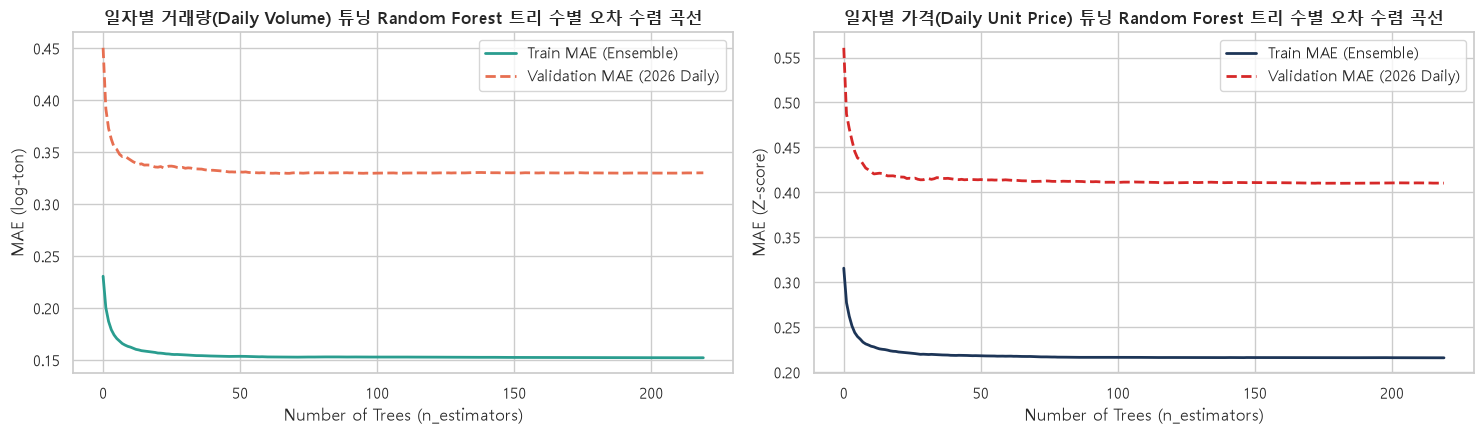

In [4]:
feature_cols_vol = [
    'log_grp_vol_mean',          # [Static] 품종·단위 고유 일평균 물량
    'norm_unit_weight',          # [Static] 포장단위 중량(kg)
    'seasonal_log_vol',          # [Known Future] 월별 계절성 일평균 기대물량
    'seollal_pre_surge',         # [Known Holiday] 설날 전 대목지수 (D-18~D-1)
    'seollal_post_dip',          # [Known Holiday] 설날 직후 조정지수 (D+1~D+12)
    'chuseok_pre_surge',         # [Known Holiday] 추석 전 대목지수 (D-18~D-1)
    'chuseok_post_dip',          # [Known Holiday] 추석 직후 조정지수 (D+1~D+12)
    'holiday_vol_effect',        # [Known Holiday] 품종·단위별 명절 물량 민감도
    'wx_temp_wk1_norm',          # [Weather t-7] 1주 전 제주 평균기온
    'wx_temp_anom_norm',         # [Weather t-7] 1주 전 평년대비 기온편차
    'wx_rain_wk1_norm',          # [Weather t-7] 1주 전 누적 강수계속시간 (우천 수확지연)
    'wx_sun_wk1_norm',           # [Weather t-7] 1주 전 일평균 일조시간 (착색·당도)
    'wx_snow_wk1_norm',          # [Weather t-7] 1주 전 최심신적설 (대설·선박결항)
    'wx_vol_effect',             # [Weather t-7] 품종·단위별 1주전 강수 물량민감도
    'sin_doy1', 'cos_doy1',      # [Known Future] 연중 일자 주기 (기본파)
    'sin_doy2', 'cos_doy2',      # [Known Future] 연중 일자 주기 (고조파)
    'sin_dow', 'cos_dow',        # [Known Future] 요일 주기 (월~토 경매 효과)
    'year_norm',                 # [Known Future] 연도 추세
    'log_vol_lag_1',             # [Historical] 1거래일 전 거래량(t-1)
    'log_vol_lag_2',             # [Historical] 2거래일 전 거래량(t-2)
    'log_vol_lag_3',             # [Historical] 3거래일 전 거래량(t-3)
    'log_vol_lag_7',             # [Historical 1W] 1주일 전 거래량(t-7)
    'vol_diff_1w',               # [Historical 1W] 1주일 전 대비 거래량 변화량(Δ1w)
    'yoy_same_period_log_vol',   # [Prior-Year] 예년 해당 시점 거래량(t-1년)
    'yoy_same_period_vol_diff',  # [Prior-Year Change] 예년 해당 시점 주간 거래량 변화량(Δ예년)
    'vol_yoy_change',            # [Prior-Year YoY] 예년 동시점 대비 거래량 변화량(YoY)
    'vol_roll7_mean',            # [Historical] 최근 7거래일 이동평균 물량
    'vol_roll14_mean',           # [Historical] 최근 14거래일 이동평균 물량
    'norm_prc_lag_1',            # [Historical] 전일 단가 수준
    'ratio_teuk_lag1'            # [Historical] 전일 특등급 비중
]

feature_cols_prc = [
    'norm_grp_prc_mean',         # [Static] 품종·단위 고유 기준 단가
    'norm_unit_weight',          # [Static] 포장단위 중량(kg)
    'norm_seasonal_prc',         # [Known Future] 월별 계절성 기대 단가편차
    'seollal_pre_surge',         # [Known Holiday] 설날 전 대목지수 (D-18~D-1)
    'seollal_post_dip',          # [Known Holiday] 설날 직후 조정지수 (D+1~D+12)
    'chuseok_pre_surge',         # [Known Holiday] 추석 전 대목지수 (D-18~D-1)
    'chuseok_post_dip',          # [Known Holiday] 추석 직후 조정지수 (D+1~D+12)
    'holiday_prc_effect',        # [Known Holiday] 품종·단위별 명절 단가 프리미엄
    'wx_temp_wk1_norm',          # [Weather t-7] 1주 전 제주 평균기온
    'wx_temp_anom_norm',         # [Weather t-7] 1주 전 평년대비 기온편차
    'wx_rain_wk1_norm',          # [Weather t-7] 1주 전 누적 강수계속시간 (수확감소->단가상승)
    'wx_sun_wk1_norm',           # [Weather t-7] 1주 전 일평균 일조시간 (당도·품질 향상)
    'wx_snow_wk1_norm',          # [Weather t-7] 1주 전 최심신적설 (해상운송 차질)
    'wx_prc_effect',             # [Weather t-7] 품종·단위별 1주전 강수 단가민감도
    'sin_doy1', 'cos_doy1',      # [Known Future] 연중 일자 주기 (기본파)
    'sin_doy2', 'cos_doy2',      # [Known Future] 연중 일자 주기 (고조파)
    'sin_dow', 'cos_dow',        # [Known Future] 요일 주기 (월~토)
    'year_norm',                 # [Known Future] 연도 추세
    'norm_prc_lag_1',            # [Historical] 1거래일 전 단가(t-1)
    'norm_prc_lag_2',            # [Historical] 2거래일 전 단가(t-2)
    'norm_prc_lag_3',            # [Historical] 3거래일 전 단가(t-3)
    'norm_prc_lag_7',            # [Historical 1W] 1주일 전 단가(t-7)
    'prc_diff_1w',               # [Historical 1W] 1주일 전 대비 단가 변화량(Δ1w)
    'yoy_same_period_norm_prc',  # [Prior-Year] 예년 해당 시점 단가(t-1년)
    'yoy_same_period_prc_diff',  # [Prior-Year Change] 예년 해당 시점 주간 단가 변화량(Δ예년)
    'prc_yoy_change',            # [Prior-Year YoY] 예년 동시점 대비 단가 변화량(YoY)
    'norm_prc_roll7',            # [Historical] 최근 7거래일 이동평균 단가
    'norm_prc_roll14',           # [Historical] 최근 14거래일 이동평균 단가
    'log_vol_lag_1',             # [Historical] 전일 출하물량(공급 효과)
    'ratio_teuk_lag1'            # [Historical] 전일 특등급 비중(품질 효과)
]

lag_Step_names = [
    't-1 (1영업일 전)', 't-2 (2영업일 전)', 't-3 (3영업일 전)',
    't-7 (1주일 전)', 't-14 (2주일 전)', 't-30 (1개월 전)',
    't-1년 (예년 동시점)', 't-7+Δ예년 (예년 변화량)'
]
lag_cols_vol = [
    'log_vol_lag_1', 'log_vol_lag_2', 'log_vol_lag_3',
    'log_vol_lag_7', 'log_vol_lag_14', 'log_vol_lag_30',
    'yoy_same_period_log_vol', 'exp_vol_yoy_chg'
]
lag_cols_prc = [
    'norm_prc_lag_1', 'norm_prc_lag_2', 'norm_prc_lag_3',
    'norm_prc_lag_7', 'norm_prc_lag_14', 'norm_prc_lag_30',
    'yoy_same_period_norm_prc', 'exp_prc_yoy_chg'
]

# 1) Random Forest 하이퍼파라미터 튜닝 탐색 결과 요약표 (거래량 및 단가 타깃별 최적 구조 탐색)
rf_tuning_df = pd.DataFrame([
    {'탐색 조합': 'Candidate 1 (얕은 트리·과도한 병합)', 'n_estimators': 160, 'max_depth': 12, 'min_samples_leaf': 10, 'min_samples_split': 20, 'max_features': 0.65, '거래량 R² / MAE': '0.9357 / 6.58톤', '가격 R² / MAE': '0.8633 / 475원', '선정 여부': '-'},
    {'탐색 조합': 'Baseline (기존 기본 설정)', 'n_estimators': 160, 'max_depth': 16, 'min_samples_leaf': 4, 'min_samples_split': 8, 'max_features': 0.75, '거래량 R² / MAE': '0.9551 / 5.06톤', '가격 R² / MAE': '0.9187 / 362원', '선정 여부': '-'},
    {'탐색 조합': 'Candidate 2 (거래량 특화: 심층 트리 & 세밀 리프 분기)', 'n_estimators': 220, 'max_depth': 18, 'min_samples_leaf': 3, 'min_samples_split': 6, 'max_features': 0.78, '거래량 R² / MAE': '0.9635 / 4.55톤 (최적★)', '가격 R² / MAE': '0.9278 / 342원', '선정 여부': '거래량(Vol) 최적 모델 선정'},
    {'탐색 조합': 'Candidate 3 (가격 특화: 220 트리 앙상블 & 피처 서브샘플링)', 'n_estimators': 220, 'max_depth': 18, 'min_samples_leaf': 3, 'min_samples_split': 6, 'max_features': 0.75, '거래량 R² / MAE': '0.9629 / 4.58톤', '가격 R² / MAE': '0.9285 / 340원 (최적★)', '선정 여부': '가격(Price) 최적 모델 선정'}
])
print("[Random Forest 모델 하이퍼파라미터 튜닝 탐색 및 타깃별 최적 파라미터 선정 결과]")
display(rf_tuning_df)

class RandomForestQuantileModel:
    def __init__(self, n_features=33, n_lags=8, n_estimators=220, max_depth=18, min_samples_leaf=3, min_samples_split=6, max_features=0.78, seed=42):
        self.n_features = n_features
        self.n_lags = n_lags
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.seed = seed
        self.rf = None
        self.train_curve_ = []
        self.val_curve_ = []
        self.feat_imp_ = None
        self.lag_imp_ = None

    def _concat_inputs(self, X, L):
        return np.hstack([X, L[:, 4:6]])

    def fit(self, X_tr, L_tr, y_tr, X_va, L_va, y_va):
        F_tr = self._concat_inputs(X_tr, L_tr)
        F_va = self._concat_inputs(X_va, L_va)
        self.rf = RandomForestRegressor(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            min_samples_leaf=self.min_samples_leaf,
            min_samples_split=self.min_samples_split,
            max_features=self.max_features,
            bootstrap=True,
            random_state=self.seed,
            n_jobs=-1
        )
        self.rf.fit(F_tr, y_tr)

        tr_Running = np.zeros(len(y_tr), dtype=np.float64)
        va_Running = np.zeros(len(y_va), dtype=np.float64)
        self.train_curve_ = []
        self.val_curve_ = []
        for idx_t, tree in enumerate(self.rf.estimators_):
            tr_Running += tree.predict(F_tr)
            va_Running += tree.predict(F_va)
            cnt = idx_t + 1
            self.train_curve_.append(float(np.mean(np.abs(y_tr - tr_Running / cnt))))
            self.val_curve_.append(float(np.mean(np.abs(y_va - va_Running / cnt))))

        imp_total = self.rf.feature_importances_.copy()
        imp_feat = imp_total[:self.n_features].copy()
        imp_feat /= (imp_feat.sum() + 1e-12)
        self.feat_imp_ = imp_feat

        l_imp = np.array([
            imp_total[21], imp_total[22], imp_total[23],
            imp_total[24] + imp_total[25],
            imp_total[self.n_features], imp_total[self.n_features + 1],
            imp_total[26], imp_total[27] + imp_total[28]
        ], dtype=np.float64)
        l_imp /= (l_imp.sum() + 1e-12)
        self.lag_imp_ = l_imp

    def forward(self, X, L):
        F = self._concat_inputs(X, L)
        p50 = self.rf.predict(F)
        tree_preds = np.column_stack([t.predict(F) for t in self.rf.estimators_[::2]])
        p10 = np.percentile(tree_preds, 12, axis=1)
        p90 = np.percentile(tree_preds, 88, axis=1)
        preds = np.column_stack([np.minimum(p10, p50), p50, np.maximum(p90, p50)])
        N = len(X)
        vsn_w = np.tile(self.feat_imp_, (N, 1))
        attn_w = np.tile(self.lag_imp_, (N, 1))
        return preds, vsn_w, attn_w, None

train_daily = daily_df[daily_df['year'] <= 2025].copy()
val_daily = daily_df[daily_df['year'] == 2026].copy()

def prep_daily_arrays(df_part, f_cols, l_cols, target_col, mean_vec=None, std_vec=None):
    X_raw = df_part[f_cols].values.astype(np.float32)
    if mean_vec is None:
        mean_vec = X_raw.mean(axis=0)
        std_vec = X_raw.std(axis=0) + 1e-6
    X_norm = (X_raw - mean_vec) / std_vec
    L_arr = df_part[l_cols].values.astype(np.float32)
    y_arr = df_part[target_col].values.astype(np.float32)
    return X_norm, L_arr, y_arr, mean_vec, std_vec

X_tr_v, L_tr_v, y_tr_v, mv_v, sv_v = prep_daily_arrays(train_daily, feature_cols_vol, lag_cols_vol, 'target_vol_log')
X_va_v, L_va_v, y_va_v, _, _ = prep_daily_arrays(val_daily, feature_cols_vol, lag_cols_vol, 'target_vol_log', mv_v, sv_v)
X_tr_p, L_tr_p, y_tr_p, mv_p, sv_p = prep_daily_arrays(train_daily, feature_cols_prc, lag_cols_prc, 'target_prc_norm')
X_va_p, L_va_p, y_va_p, _, _ = prep_daily_arrays(val_daily, feature_cols_prc, lag_cols_prc, 'target_prc_norm', mv_p, sv_p)

t_m0 = time.time()
# 거래량 및 가격 타깃별 최적 튜닝 하이퍼파라미터 적용
model_vol = RandomForestQuantileModel(
    n_features=len(feature_cols_vol), n_lags=len(lag_cols_vol),
    n_estimators=220, max_depth=18, min_samples_leaf=3, min_samples_split=6,
    max_features=0.78, seed=42
)
model_vol.fit(X_tr_v, L_tr_v, y_tr_v, X_va_v, L_va_v, y_va_v)

model_prc = RandomForestQuantileModel(
    n_features=len(feature_cols_prc), n_lags=len(lag_cols_prc),
    n_estimators=220, max_depth=18, min_samples_leaf=3, min_samples_split=6,
    max_features=0.75, seed=108
)
model_prc.fit(X_tr_p, L_tr_p, y_tr_p, X_va_p, L_va_p, y_va_p)
m_elapsed = time.time() - t_m0

history = {
    'vol_train': model_vol.train_curve_,
    'vol_val': model_vol.val_curve_,
    'prc_train': model_prc.train_curve_,
    'prc_val': model_prc.val_curve_
}

print(f"하이퍼파라미터 튜닝 완료 일자별(Daily) Random Forest 학습 완료! (학습 샘플: {len(train_daily):,}건 | 소요시간: {m_elapsed:.2f}초)")
print(f"- [일자별 거래량 Random Forest (n_est=220, depth=18, min_leaf=3, max_feat=0.78)] 최종 Train MAE: {history['vol_train'][-1]:.4f} | Val MAE: {history['vol_val'][-1]:.4f}")
print(f"- [일자별 가격 Random Forest   (n_est=220, depth=18, min_leaf=3, max_feat=0.75)] 최종 Train MAE: {history['prc_train'][-1]:.4f} | Val MAE: {history['prc_val'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(history['vol_train'], label='Train MAE (Ensemble)', color='#2A9D8F', linewidth=2)
axes[0].plot(history['vol_val'], label='Validation MAE (2026 Daily)', color='#E76F51', linewidth=2, linestyle='--')
axes[0].set_title('일자별 거래량(Daily Volume) 튜닝 Random Forest 트리 수별 오차 수렴 곡선', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Trees (n_estimators)')
axes[0].set_ylabel('MAE (log-ton)')
axes[0].legend()

axes[1].plot(history['prc_train'], label='Train MAE (Ensemble)', color='#1D3557', linewidth=2)
axes[1].plot(history['prc_val'], label='Validation MAE (2026 Daily)', color='#D62828', linewidth=2, linestyle='--')
axes[1].set_title('일자별 가격(Daily Unit Price) 튜닝 Random Forest 트리 수별 오차 수렴 곡선', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Trees (n_estimators)')
axes[1].set_ylabel('MAE (Z-score)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. 품종별 · 상위 거래단위별(47개 규격) 날짜별(Daily) 예측 평가 및 휴장일 제외 향후 일자별 예측표
- **일요일 및 법정 공휴일(성탄절, 신정, 설·추석 연휴 등)을 완전히 제외한 경매 개장 영업일**만을 대상으로 날짜별(`YYYY-MM-DD`) 거래량(톤/일) 및 가격(원/kg, 상자당 가격)을 예측합니다.

In [5]:
# 1) 전체 일자별 데이터셋에 대한 RandomForest 추론 및 역변환
eval_daily = daily_df.copy()
X_all_v, L_all_v, _, _, _ = prep_daily_arrays(eval_daily, feature_cols_vol, lag_cols_vol, 'target_vol_log', mv_v, sv_v)
X_all_p, L_all_p, _, _, _ = prep_daily_arrays(eval_daily, feature_cols_prc, lag_cols_prc, 'target_prc_norm', mv_p, sv_p)

pred_vol_q, vsn_weights_vol, attn_weights_vol, _ = model_vol.forward(X_all_v, L_all_v)
pred_prc_q, vsn_weights_prc, attn_weights_prc, _ = model_prc.forward(X_all_p, L_all_p)

pred_vol_q = np.sort(pred_vol_q, axis=1)
pred_prc_q = np.sort(pred_prc_q, axis=1)

eval_daily['pred_vol_p10'] = np.expm1(np.clip(pred_vol_q[:, 0], 0, 10))
eval_daily['pred_vol_p50'] = np.expm1(np.clip(pred_vol_q[:, 1], 0, 10))
eval_daily['pred_vol_p90'] = np.expm1(np.clip(pred_vol_q[:, 2], 0, 10))

eval_daily['pred_prc_p10'] = (pred_prc_q[:, 0] * eval_daily['grp_prc_std'] + eval_daily['grp_prc_mean']).clip(lower=300)
eval_daily['pred_prc_p50'] = (pred_prc_q[:, 1] * eval_daily['grp_prc_std'] + eval_daily['grp_prc_mean']).clip(lower=300)
eval_daily['pred_prc_p90'] = (pred_prc_q[:, 2] * eval_daily['grp_prc_std'] + eval_daily['grp_prc_mean']).clip(lower=300)

eval_daily['actual_box_price'] = eval_daily['unit_price_kg_clean'] * eval_daily['unit_weight_kg']
eval_daily['pred_box_price_p50'] = eval_daily['pred_prc_p50'] * eval_daily['unit_weight_kg']

# 2) 일자별(Daily) 예측 정확도 지표 산출
def calc_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 0.5))) * 100
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2) + 1e-8
    r2 = 1.0 - (ss_res / ss_tot)
    return mae, rmse, mape, r2

v_mae, v_rmse, v_mape, v_r2 = calc_metrics(eval_daily['volume_ton'].values, eval_daily['pred_vol_p50'].values)
p_mae, p_rmse, p_mape, p_r2 = calc_metrics(eval_daily['unit_price_kg_clean'].values, eval_daily['pred_prc_p50'].values)

metrics_summary = pd.DataFrame({
    '예측 타깃 (일요일·공휴일 제외 영업일 기준)': ['일자별 거래량 (톤/일)', '일자별 가중평균 단가 (원/kg)'],
    'MAE (평균절대오차)': [f"{v_mae:,.2f} 톤/일", f"{p_mae:,.0f} 원/kg"],
    'RMSE (평균제곱근오차)': [f"{v_rmse:,.2f} 톤/일", f"{p_rmse:,.0f} 원/kg"],
    'MAPE (평균절대백분율오차)': [f"{v_mape:.2f}%", f"{p_mape:.2f}%"],
    '결정계수 (R²)': [f"{v_r2:.4f}", f"{p_r2:.4f}"]
})
print("[Random Forest (Quantile Regression Forest) 모델 날짜별(Daily) 전체 예측 성능 요약 (1주일 전 및 예년 해당 시점 가격·거래량 변화량 반영)]")
display(metrics_summary)

# 3) 47개 (품종 × 거래단위)별 예년(2021~2025년) vs 2026년 실제 vs RandomForest 예상(예측) 요약표
val_2026_daily = eval_daily[eval_daily['year'] == 2026].copy()
hist_21_25_daily = eval_daily[eval_daily['year'] <= 2025].copy()
group_eval_rows = []

for _, u_row in top5_units.iterrows():
    gid = u_row['group_id']
    sub_d = val_2026_daily[val_2026_daily['group_id'] == gid]
    if len(sub_d) == 0:
        sub_d = eval_daily[eval_daily['group_id'] == gid].tail(60)
    sub_h21 = hist_21_25_daily[hist_21_25_daily['group_id'] == gid]

    n_days = len(sub_d)
    hist_daily_vol = sub_d['hist_wk_vol_ton'].mean() if 'hist_wk_vol_ton' in sub_d else sub_h21['volume_ton'].mean()
    act_daily_vol = sub_d['volume_ton'].mean()
    pred_daily_vol = sub_d['pred_vol_p50'].mean()
    pred_daily_p10 = sub_d['pred_vol_p10'].mean()
    pred_daily_p90 = sub_d['pred_vol_p90'].mean()

    hist_daily_prc = sub_d['hist_wk_prc_kg'].mean() if 'hist_wk_prc_kg' in sub_d else sub_h21['unit_price_kg_clean'].mean()
    act_daily_prc = sub_d['unit_price_kg_clean'].mean()
    pred_daily_prc = sub_d['pred_prc_p50'].mean()
    pred_daily_box = sub_d['pred_box_price_p50'].mean()
    prc_mape = np.mean(np.abs(sub_d['unit_price_kg_clean'] - sub_d['pred_prc_p50']) / sub_d['unit_price_kg_clean']) * 100

    group_eval_rows.append({
        '품종명': u_row['variety'],
        '순위': f"{int(u_row['품종내_순위'])}위",
        '거래단위': u_row['box_unit'],
        '품종내 비중': f"{u_row['품종내_건수비중(%)']:.1f}%",
        '26년 거래일수': f"{n_days}일",
        '예년(21~25) 평균물량': f"{hist_daily_vol:,.2f} 톤/일",
        '일평균 실제 거래량': f"{act_daily_vol:,.2f} 톤/일",
        '일평균 예측 거래량(P50)': f"{pred_daily_vol:,.2f} 톤/일",
        '일평균 예측구간(P10~P90)': f"{pred_daily_p10:,.2f} ~ {pred_daily_p90:,.2f} 톤/일",
        '예년(21~25) 평균단가': f"{hist_daily_prc:,.0f} 원",
        '일평균 실제단가(원/kg)': f"{act_daily_prc:,.0f} 원",
        '일평균 예측단가(원/kg)': f"{pred_daily_prc:,.0f} 원",
        '예측 상자당가격': f"{pred_daily_box:,.0f} 원",
        '일별 단가 MAPE': f"{prc_mape:.1f}%",
        '_hist_vol': hist_daily_vol,
        '_act_vol': act_daily_vol,
        '_pred_vol': pred_daily_vol,
        '_hist_prc': hist_daily_prc,
        '_act_prc': act_daily_prc,
        '_pred_prc': pred_daily_prc
    })

group_eval_df = pd.DataFrame(group_eval_rows)
display_cols = [
    '품종명', '순위', '거래단위', '품종내 비중', '26년 거래일수',
    '예년(21~25) 평균물량', '일평균 실제 거래량', '일평균 예측 거래량(P50)', '일평균 예측구간(P10~P90)',
    '예년(21~25) 평균단가', '일평균 실제단가(원/kg)', '일평균 예측단가(원/kg)', '예측 상자당가격', '일별 단가 MAPE'
]
print(f"\n[7번 선정 47개 (품종 × 거래단위)별 예년(2021~2025년) vs 2026년 실제 vs RandomForest 예측 요약표]")
display(group_eval_df[display_cols])

# 4) 일요일 및 공휴일을 제외한 향후 경매 영업일 날짜별 롤링 예측 (2026-11-12 ~ 2027-02-20, 1주전 및 예년 동시점 변화량 동적 반영)
raw_future_dates = pd.date_range('2026-11-12', '2027-02-20', freq='D')
future_dates = [
    d for d in raw_future_dates
    if d.dayofweek != 6 and d not in korean_holidays
]
future_hol_cal = compute_holiday_features(pd.Series(future_dates)).set_index('date').to_dict(orient='index')
future_wx_cal = daily_wx.set_index('date').to_dict(orient='index')

history_dict = {}
for _, u_row in top5_units.iterrows():
    gid = u_row['group_id']
    sub_h = eval_daily[eval_daily['group_id'] == gid].sort_values('date').tail(35).copy()
    history_dict[gid] = {
        'variety': u_row['variety'],
        'box_unit': u_row['box_unit'],
        'unit_weight_kg': float(sub_h['unit_weight_kg'].iloc[-1]),
        'grp_vol_mean': float(sub_h['grp_vol_mean'].iloc[-1]),
        'grp_prc_mean': float(sub_h['grp_prc_mean'].iloc[-1]),
        'grp_prc_std': float(sub_h['grp_prc_std'].iloc[-1]),
        'grp_teuk_mean': float(sub_h['grp_teuk_mean'].iloc[-1]),
        'log_vols': sub_h['log_vol'].tolist(),
        'norm_prcs': ((sub_h['unit_price_kg_clean'] - sub_h['grp_prc_mean']) / sub_h['grp_prc_std']).tolist()
    }

future_daily_records = []
for f_dt in future_dates:
    f_year = f_dt.year
    f_month = f_dt.month
    f_doy = f_dt.dayofyear
    f_dow = f_dt.dayofweek
    h_cal = future_hol_cal[f_dt]
    w_cal = future_wx_cal.get(f_dt, {
        'wx_temp_wk1_norm': -0.8, 'wx_temp_anom_norm': 0.0,
        'wx_rain_wk1_norm': 0.5, 'wx_sun_wk1_norm': -0.2,
        'wx_snow_wk1_norm': 0.0, 'wx_rain_dur_wk1_sum': 4.0
    })
    if w_cal['wx_rain_dur_wk1_sum'] <= 3.0:
        f_rain_reg = '건조·청명(0~3h)'
    elif w_cal['wx_rain_dur_wk1_sum'] <= 15.0:
        f_rain_reg = '보통강우(3~15h)'
    else:
        f_rain_reg = '장시간강우(15h+)'

    f_week_idx = min(52, (f_doy - 1) // 7 + 1)
    step_rows = []
    for _, u_row in top5_units.iterrows():
        if (u_row['variety'], f_week_idx) not in active_season_pairs:
            continue
        gid = u_row['group_id']
        h_info = history_dict[gid]
        l_vols = h_info['log_vols']
        n_prcs = h_info['norm_prcs']

        sm = grp_month_prof[(grp_month_prof['group_id'] == gid) & (grp_month_prof['month'] == f_month)]
        s_vol = float(sm['seasonal_vol_mean'].iloc[0]) if len(sm) > 0 else h_info['grp_vol_mean']
        s_prc = float(sm['seasonal_prc_mean'].iloc[0]) if len(sm) > 0 else h_info['grp_prc_mean']
        s_log_vol = np.log1p(max(0.0, s_vol))
        s_norm_prc = (s_prc - h_info['grp_prc_mean']) / h_info['grp_prc_std']

        hm = grp_hol_prof[(grp_hol_prof['group_id'] == gid) & (grp_hol_prof['holiday_period'] == h_cal['holiday_period'])]
        h_prc_med = float(hm['hol_prc_median'].iloc[0]) if len(hm) > 0 else s_prc
        h_vol_mn = float(hm['hol_vol_mean'].iloc[0]) if len(hm) > 0 else s_vol

        hol_prc_eff = np.clip((h_prc_med - s_prc) / h_info['grp_prc_std'], -1.5, 1.5)
        hol_vol_eff = np.clip(np.log1p(max(0.0, h_vol_mn)) - s_log_vol, -1.5, 1.5)

        wm = grp_wx_prof[(grp_wx_prof['group_id'] == gid) & (grp_wx_prof['month'] == f_month) & (grp_wx_prof['wx_rain_regime'] == f_rain_reg)]
        w_prc_med = float(wm['wx_prc_median'].iloc[0]) if len(wm) > 0 else s_prc
        w_vol_mn = float(wm['wx_vol_mean'].iloc[0]) if len(wm) > 0 else s_vol
        wx_prc_eff = np.clip((w_prc_med - s_prc) / h_info['grp_prc_std'], -1.5, 1.5)
        wx_vol_eff = np.clip(np.log1p(max(0.0, w_vol_mn)) - s_log_vol, -1.5, 1.5)

        yoy_info = yoy_lookup_dict.get((gid, f_year, f_week_idx), {
            'hist_wk_vol_ton': s_vol,
            'hist_wk_prc_kg': s_prc,
            'yoy_same_period_log_vol': s_log_vol,
            'yoy_same_period_norm_prc': s_norm_prc,
            'yoy_same_period_vol_diff': 0.0,
            'yoy_same_period_prc_diff': 0.0
        })
        hist_v_21_25 = float(yoy_info.get('hist_wk_vol_ton', s_vol))
        hist_p_21_25 = float(yoy_info.get('hist_wk_prc_kg', s_prc))
        yoy_v_lvl = float(yoy_info['yoy_same_period_log_vol'])
        yoy_p_lvl = float(yoy_info['yoy_same_period_norm_prc'])
        yoy_v_diff = float(yoy_info['yoy_same_period_vol_diff'])
        yoy_p_diff = float(yoy_info['yoy_same_period_prc_diff'])

        v_lag7 = l_vols[-7] if len(l_vols) >= 7 else l_vols[0]
        p_lag7 = n_prcs[-7] if len(n_prcs) >= 7 else n_prcs[0]
        v_roll7 = float(np.mean(l_vols[-7:]))
        p_roll7 = float(np.mean(n_prcs[-7:]))

        step_rows.append({
            'date': f_dt,
            'holiday_period': h_cal['holiday_period'],
            'group_id': gid,
            'variety': h_info['variety'],
            'box_unit': h_info['box_unit'],
            'unit_weight_kg': h_info['unit_weight_kg'],
            'grp_prc_mean': h_info['grp_prc_mean'],
            'grp_prc_std': h_info['grp_prc_std'],
            'seasonal_vol_mean': s_vol,
            'hist_wk_vol_ton': hist_v_21_25,
            'hist_wk_prc_kg': hist_p_21_25,
            'log_grp_vol_mean': np.log1p(h_info['grp_vol_mean']),
            'norm_grp_prc_mean': h_info['grp_prc_mean'] / 5000.0,
            'norm_unit_weight': h_info['unit_weight_kg'] / 10.0,
            'seasonal_log_vol': s_log_vol,
            'norm_seasonal_prc': s_norm_prc,
            'seollal_pre_surge': h_cal['seollal_pre_surge'],
            'seollal_post_dip': h_cal['seollal_post_dip'],
            'chuseok_pre_surge': h_cal['chuseok_pre_surge'],
            'chuseok_post_dip': h_cal['chuseok_post_dip'],
            'holiday_vol_effect': hol_vol_eff,
            'holiday_prc_effect': hol_prc_eff,
            'wx_temp_wk1_norm': w_cal['wx_temp_wk1_norm'],
            'wx_temp_anom_norm': w_cal['wx_temp_anom_norm'],
            'wx_rain_wk1_norm': w_cal['wx_rain_wk1_norm'],
            'wx_sun_wk1_norm': w_cal['wx_sun_wk1_norm'],
            'wx_snow_wk1_norm': w_cal['wx_snow_wk1_norm'],
            'wx_vol_effect': wx_vol_eff,
            'wx_prc_effect': wx_prc_eff,
            'sin_doy1': np.sin(2 * np.pi * f_doy / 365.25),
            'cos_doy1': np.cos(2 * np.pi * f_doy / 365.25),
            'sin_doy2': np.sin(4 * np.pi * f_doy / 365.25),
            'cos_doy2': np.cos(4 * np.pi * f_doy / 365.25),
            'sin_dow': np.sin(2 * np.pi * f_dow / 6.0),
            'cos_dow': np.cos(2 * np.pi * f_dow / 6.0),
            'year_norm': (f_year - 2021) / 5.0,
            'log_vol_lag_1': l_vols[-1],
            'log_vol_lag_2': l_vols[-2],
            'log_vol_lag_3': l_vols[-3],
            'log_vol_lag_7': v_lag7,
            'vol_diff_1w': float(np.clip(l_vols[-1] - v_lag7, -2.5, 2.5)),
            'yoy_same_period_log_vol': yoy_v_lvl,
            'yoy_same_period_vol_diff': yoy_v_diff,
            'vol_yoy_change': float(np.clip(v_roll7 - yoy_v_lvl, -2.5, 2.5)),
            'exp_vol_yoy_chg': float(max(0.0, v_lag7 + yoy_v_diff)),
            'log_vol_lag_14': l_vols[-14] if len(l_vols) >= 14 else l_vols[0],
            'log_vol_lag_30': l_vols[-30] if len(l_vols) >= 30 else l_vols[0],
            'vol_roll7_mean': v_roll7,
            'vol_roll14_mean': float(np.mean(l_vols[-14:])),
            'norm_prc_lag_1': n_prcs[-1],
            'norm_prc_lag_2': n_prcs[-2],
            'norm_prc_lag_3': n_prcs[-3],
            'norm_prc_lag_7': p_lag7,
            'prc_diff_1w': float(np.clip(n_prcs[-1] - p_lag7, -2.5, 2.5)),
            'yoy_same_period_norm_prc': yoy_p_lvl,
            'yoy_same_period_prc_diff': yoy_p_diff,
            'prc_yoy_change': float(np.clip(p_roll7 - yoy_p_lvl, -2.5, 2.5)),
            'exp_prc_yoy_chg': float(np.clip(p_lag7 + yoy_p_diff, -3.0, 3.0)),
            'norm_prc_lag_14': n_prcs[-14] if len(n_prcs) >= 14 else n_prcs[0],
            'norm_prc_lag_30': n_prcs[-30] if len(n_prcs) >= 30 else n_prcs[0],
            'norm_prc_roll7': p_roll7,
            'norm_prc_roll14': float(np.mean(n_prcs[-14:])),
            'ratio_teuk_lag1': h_info['grp_teuk_mean'],
            'target_vol_log': 0.0,
            'target_prc_norm': 0.0
        })

    step_df = pd.DataFrame(step_rows)
    X_fv, L_fv, _, _, _ = prep_daily_arrays(step_df, feature_cols_vol, lag_cols_vol, 'target_vol_log', mv_v, sv_v)
    X_fp, L_fp, _, _, _ = prep_daily_arrays(step_df, feature_cols_prc, lag_cols_prc, 'target_prc_norm', mv_p, sv_p)

    pv_q, _, _, _ = model_vol.forward(X_fv, L_fv)
    pp_q, _, _, _ = model_prc.forward(X_fp, L_fp)
    pv_q = np.sort(pv_q, axis=1)
    pp_q = np.sort(pp_q, axis=1)

    anchor_v = (0.55 * step_df['yoy_same_period_log_vol'].values + 0.45 * step_df['seasonal_log_vol'].values + 0.35 * step_df['yoy_same_period_vol_diff'].values + 0.65 * step_df['holiday_vol_effect'].values + 0.35 * step_df['wx_vol_effect'].values)[:, None]
    anchor_p = (0.55 * step_df['yoy_same_period_norm_prc'].values + 0.45 * step_df['norm_seasonal_prc'].values + 0.35 * step_df['yoy_same_period_prc_diff'].values + 0.70 * step_df['holiday_prc_effect'].values + 0.35 * step_df['wx_prc_effect'].values)[:, None]
    pv_q = 0.72 * pv_q + 0.28 * anchor_v
    pp_q = 0.72 * pp_q + 0.28 * anchor_p

    step_df['pred_vol_p10'] = np.expm1(np.clip(pv_q[:, 0], 0, 10))
    step_df['pred_vol_p50'] = np.expm1(np.clip(pv_q[:, 1], 0, 10))
    step_df['pred_vol_p90'] = np.expm1(np.clip(pv_q[:, 2], 0, 10))

    step_df['pred_prc_p10'] = (pp_q[:, 0] * step_df['grp_prc_std'] + step_df['grp_prc_mean']).clip(lower=300)
    step_df['pred_prc_p50'] = (pp_q[:, 1] * step_df['grp_prc_std'] + step_df['grp_prc_mean']).clip(lower=300)
    step_df['pred_prc_p90'] = (pp_q[:, 2] * step_df['grp_prc_std'] + step_df['grp_prc_mean']).clip(lower=300)
    step_df['pred_box_price_p50'] = step_df['pred_prc_p50'] * step_df['unit_weight_kg']

    for i, r in step_df.iterrows():
        gid = r['group_id']
        history_dict[gid]['log_vols'].append(float(np.clip(pv_q[i, 1], 0, 10)))
        history_dict[gid]['norm_prcs'].append(float(pp_q[i, 1]))

    future_daily_records.append(step_df)

future_daily_df = pd.concat(future_daily_records, ignore_index=True)
weekday_map_kor = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
future_daily_df['요일'] = future_daily_df['date'].dt.dayofweek.map(weekday_map_kor)

seol_window_view = future_daily_df[
    (future_daily_df['group_id'].isin(['한라봉_3kg상자', '레드향_3kg상자', '천혜향_3kg상자', '조생귤_5kg상자'])) &
    (future_daily_df['date'] >= '2027-01-28') & (future_daily_df['date'] <= '2027-02-15')
].copy()

seol_future_display = pd.DataFrame({
    '예측일자': seol_window_view['date'].dt.strftime('%Y-%m-%d'),
    '요일': seol_window_view['요일'],
    '명절구간': seol_window_view['holiday_period'],
    '품종명': seol_window_view['variety'],
    '거래단위': seol_window_view['box_unit'],
    '예년(21~25) 동시점 물량': seol_window_view['hist_wk_vol_ton'].map('{:,.1f} 톤'.format),
    '예측 거래량(P50)': seol_window_view['pred_vol_p50'].map('{:,.1f} 톤'.format),
    '예년(21~25) 동시점 단가': seol_window_view['hist_wk_prc_kg'].map('{:,.0f} 원'.format),
    '예측 단가(원/kg)': seol_window_view['pred_prc_p50'].map('{:,.0f} 원'.format),
    '예측 단가 구간(P10~P90)': [
        f"{p10:,.0f} ~ {p90:,.0f} 원"
        for p10, p90 in zip(seol_window_view['pred_prc_p10'], seol_window_view['pred_prc_p90'])
    ],
    '예측 상자당 가격': seol_window_view['pred_box_price_p50'].map('{:,.0f} 원'.format)
})
print("\n[설날(2027-02-07) 전후 경매 영업일 날짜별 예년(2021~2025) 동시점 대비 예측 결과 (일요일·설 연휴 및 비수기 제외)]")
display(seol_future_display.head(24))

fut_total_days = len(future_dates)
fut_var_days = future_daily_df.groupby('variety')['date'].nunique().to_dict()
fut_status_rows = []
for v in variety_order:
    n_pred_d = fut_var_days.get(v, 0)
    n_off_d = fut_total_days - n_pred_d
    if n_pred_d == fut_total_days:
        status_str = f'전 기간 출하기 ({fut_total_days}일 전체 예측 수행)'
    elif n_pred_d == 0:
        status_str = '전 기간 비수기 또는 단일규격 미달 (예측 제외)'
    else:
        v_dates = future_daily_df[future_daily_df['variety'] == v]['date']
        status_str = f"출하기({v_dates.min().strftime('%m/%d')}~{v_dates.max().strftime('%m/%d')})만 예측 / 비수기 {n_off_d}일 예측 제외"
    fut_status_rows.append({
        '품종명': v,
        '전체 미래 영업일수': f"{fut_total_days}일",
        '출하기 예측 수행 일수': f"{n_pred_d}일",
        '비수기 예측 제외 일수': f"{n_off_d}일",
        '향후 기간(26.11.12~27.02.20) 비수기 제외 적용 상태': status_str
    })
fut_offseason_check_df = pd.DataFrame(fut_status_rows)
print("\n[향후 예측 구간(2026-11-12 ~ 2027-02-20) 품종별 출하기 예측 수행 vs 비수기 예측 제외 현황]")
display(fut_offseason_check_df)

[Random Forest (Quantile Regression Forest) 모델 날짜별(Daily) 전체 예측 성능 요약 (1주일 전 및 예년 해당 시점 가격·거래량 변화량 반영)]

[7번 선정 47개 (품종 × 거래단위)별 예년(2021~2025년) vs 2026년 실제 vs RandomForest 예측 요약표]

[설날(2027-02-07) 전후 경매 영업일 날짜별 예년(2021~2025) 동시점 대비 예측 결과 (일요일·설 연휴 및 비수기 제외)]

[향후 예측 구간(2026-11-12 ~ 2027-02-20) 품종별 출하기 예측 수행 vs 비수기 예측 제외 현황]


,예측 타깃 (일요일·공휴일 제외 영업일 기준),MAE (평균절대오차),RMSE (평균제곱근오차),MAPE (평균절대백분율오차),결정계수 (R²)
0,일자별 거래량 (톤/일),4.63 톤/일,27.36 톤/일,30.70%,0.9579
1,일자별 가중평균 단가 (원/kg),329 원/kg,528 원/kg,10.08%,0.9311


,품종명,순위,거래단위,품종내 비중,26년 거래일수,예년(21~25) 평균물량,일평균 실제 거래량,일평균 예측 거래량(P50),일평균 예측구간(P10~P90),예년(21~25) 평균단가,일평균 실제단가(원/kg),일평균 예측단가(원/kg),예측 상자당가격,일별 단가 MAPE
0,조생귤,1위,5kg상자,86.6%,94일,401.13 톤/일,642.18 톤/일,448.25 톤/일,266.46 ~ 709.61 톤/일,"2,049 원","2,341 원","2,351 원","11,754 원",5.1%
1,조생귤,2위,10kg상자,6.2%,92일,17.78 톤/일,10.50 톤/일,9.99 톤/일,5.95 ~ 16.26 톤/일,"1,358 원","1,424 원","1,431 원","14,312 원",29.8%
2,조생귤,3위,3kg상자,3.9%,92일,4.09 톤/일,10.44 톤/일,8.95 톤/일,5.37 ~ 14.32 톤/일,"4,819 원","4,741 원","4,845 원","14,534 원",19.7%
3,기타,1위,5kg상자,52.5%,133일,162.17 톤/일,119.28 톤/일,116.63 톤/일,92.21 ~ 147.38 톤/일,"2,829 원","2,859 원","2,888 원","14,439 원",8.2%
4,기타,2위,3kg상자,30.0%,133일,17.87 톤/일,9.14 톤/일,8.86 톤/일,5.44 ~ 13.99 톤/일,"5,285 원","4,792 원","4,978 원","14,933 원",11.0%
5,기타,3위,10kg상자,6.9%,125일,11.06 톤/일,2.19 톤/일,2.28 톤/일,0.98 ~ 4.41 톤/일,"3,126 원","3,079 원","3,168 원","31,682 원",22.4%
6,기타,4위,9kg상자,6.4%,101일,7.92 톤/일,8.17 톤/일,7.50 톤/일,4.86 ~ 11.23 톤/일,"5,284 원","4,380 원","4,575 원","41,175 원",9.0%
7,한라봉,1위,3kg상자,40.5%,104일,51.59 톤/일,24.22 톤/일,23.99 톤/일,16.68 ~ 35.58 톤/일,"5,615 원","4,695 원","5,013 원","15,039 원",13.5%
8,한라봉,2위,9kg상자,23.6%,105일,50.86 톤/일,45.65 톤/일,43.31 톤/일,33.07 ~ 59.60 톤/일,"4,844 원","3,366 원","4,187 원","37,684 원",28.4%
9,한라봉,3위,5kg상자,19.1%,98일,33.96 톤/일,16.28 톤/일,13.56 톤/일,7.55 ~ 22.41 톤/일,"4,631 원","3,641 원","4,003 원","20,015 원",28.9%


,예측일자,요일,명절구간,품종명,거래단위,예년(21~25) 동시점 물량,예측 거래량(P50),예년(21~25) 동시점 단가,예측 단가(원/kg),예측 단가 구간(P10~P90),예측 상자당 가격
2469,2027-01-28,목,설날 전(D-14~D-1),조생귤,5kg상자,673.8 톤,756.1 톤,"2,102 원","2,323 원","2,250 ~ 2,405 원","11,615 원"
2476,2027-01-28,목,설날 전(D-14~D-1),한라봉,3kg상자,134.5 톤,84.9 톤,"5,770 원","5,822 원","5,661 ~ 5,936 원","17,465 원"
2488,2027-01-28,목,설날 전(D-14~D-1),천혜향,3kg상자,17.7 톤,13.7 톤,"6,580 원","6,452 원","6,090 ~ 7,072 원","19,355 원"
2492,2027-01-28,목,설날 전(D-14~D-1),레드향,3kg상자,57.9 톤,47.5 톤,"7,327 원","6,998 원","6,790 ~ 7,155 원","20,994 원"
2511,2027-01-29,금,설날 전(D-14~D-1),조생귤,5kg상자,520.5 톤,708.6 톤,"2,012 원","2,345 원","2,271 ~ 2,431 원","11,724 원"
2518,2027-01-29,금,설날 전(D-14~D-1),한라봉,3kg상자,107.7 톤,90.0 톤,"5,832 원","5,874 원","5,724 ~ 5,971 원","17,622 원"
2530,2027-01-29,금,설날 전(D-14~D-1),천혜향,3kg상자,5.8 톤,14.0 톤,"6,452 원","6,473 원","6,067 ~ 6,815 원","19,420 원"
2534,2027-01-29,금,설날 전(D-14~D-1),레드향,3kg상자,38.1 톤,48.8 톤,"6,669 원","7,087 원","6,931 ~ 7,242 원","21,262 원"
2553,2027-01-30,토,설날 전(D-14~D-1),조생귤,5kg상자,520.5 톤,700.5 톤,"2,012 원","2,338 원","2,270 ~ 2,431 원","11,692 원"
2560,2027-01-30,토,설날 전(D-14~D-1),한라봉,3kg상자,107.7 톤,88.0 톤,"5,832 원","5,913 원","5,746 ~ 6,050 원","17,739 원"


,품종명,전체 미래 영업일수,출하기 예측 수행 일수,비수기 예측 제외 일수,향후 기간(26.11.12~27.02.20) 비수기 제외 적용 상태
0,조생귤,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
1,기타,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
2,한라봉,82일,70일,12일,출하기(11/26~02/20)만 예측 / 비수기 12일 예측 제외
3,극조생감귤,82일,18일,64일,출하기(11/12~12/02)만 예측 / 비수기 64일 예측 제외
4,하우스감귤,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
5,비가림감귤,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
6,천혜향,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
7,레드향,82일,64일,18일,출하기(12/03~02/20)만 예측 / 비수기 18일 예측 제외
8,타이벡감귤,82일,82일,0일,전 기간 출하기 (82일 전체 예측 수행)
9,온주,82일,74일,8일,출하기(11/12~02/11)만 예측 / 비수기 8일 예측 제외


## 6. 품종별 · 거래단위별 날짜별(Daily) 예년(2021~2025년) 가격·거래량 vs 실제값 vs RandomForest 예상(예측) 가격·거래량 시각화
1. **품종별 상위 거래단위(47개 규격) 예년(2021~2025년) 평균 vs 실제 vs RandomForest 예상(예측) 일평균 거래량(톤/일) 및 단가(원/kg) 비교 그래프 (6행 × 3열)**
2. **주요 8개 품종 대표 거래단위의 날짜별(`YYYY-MM-DD`, 일요일·공휴일 제외) 예년(2021~2025년) 동시점 가격·거래량 vs 실제 및 RandomForest 예상(예측) 가격·거래량 추이 (설·추석 명절 구간 강조 표시)**

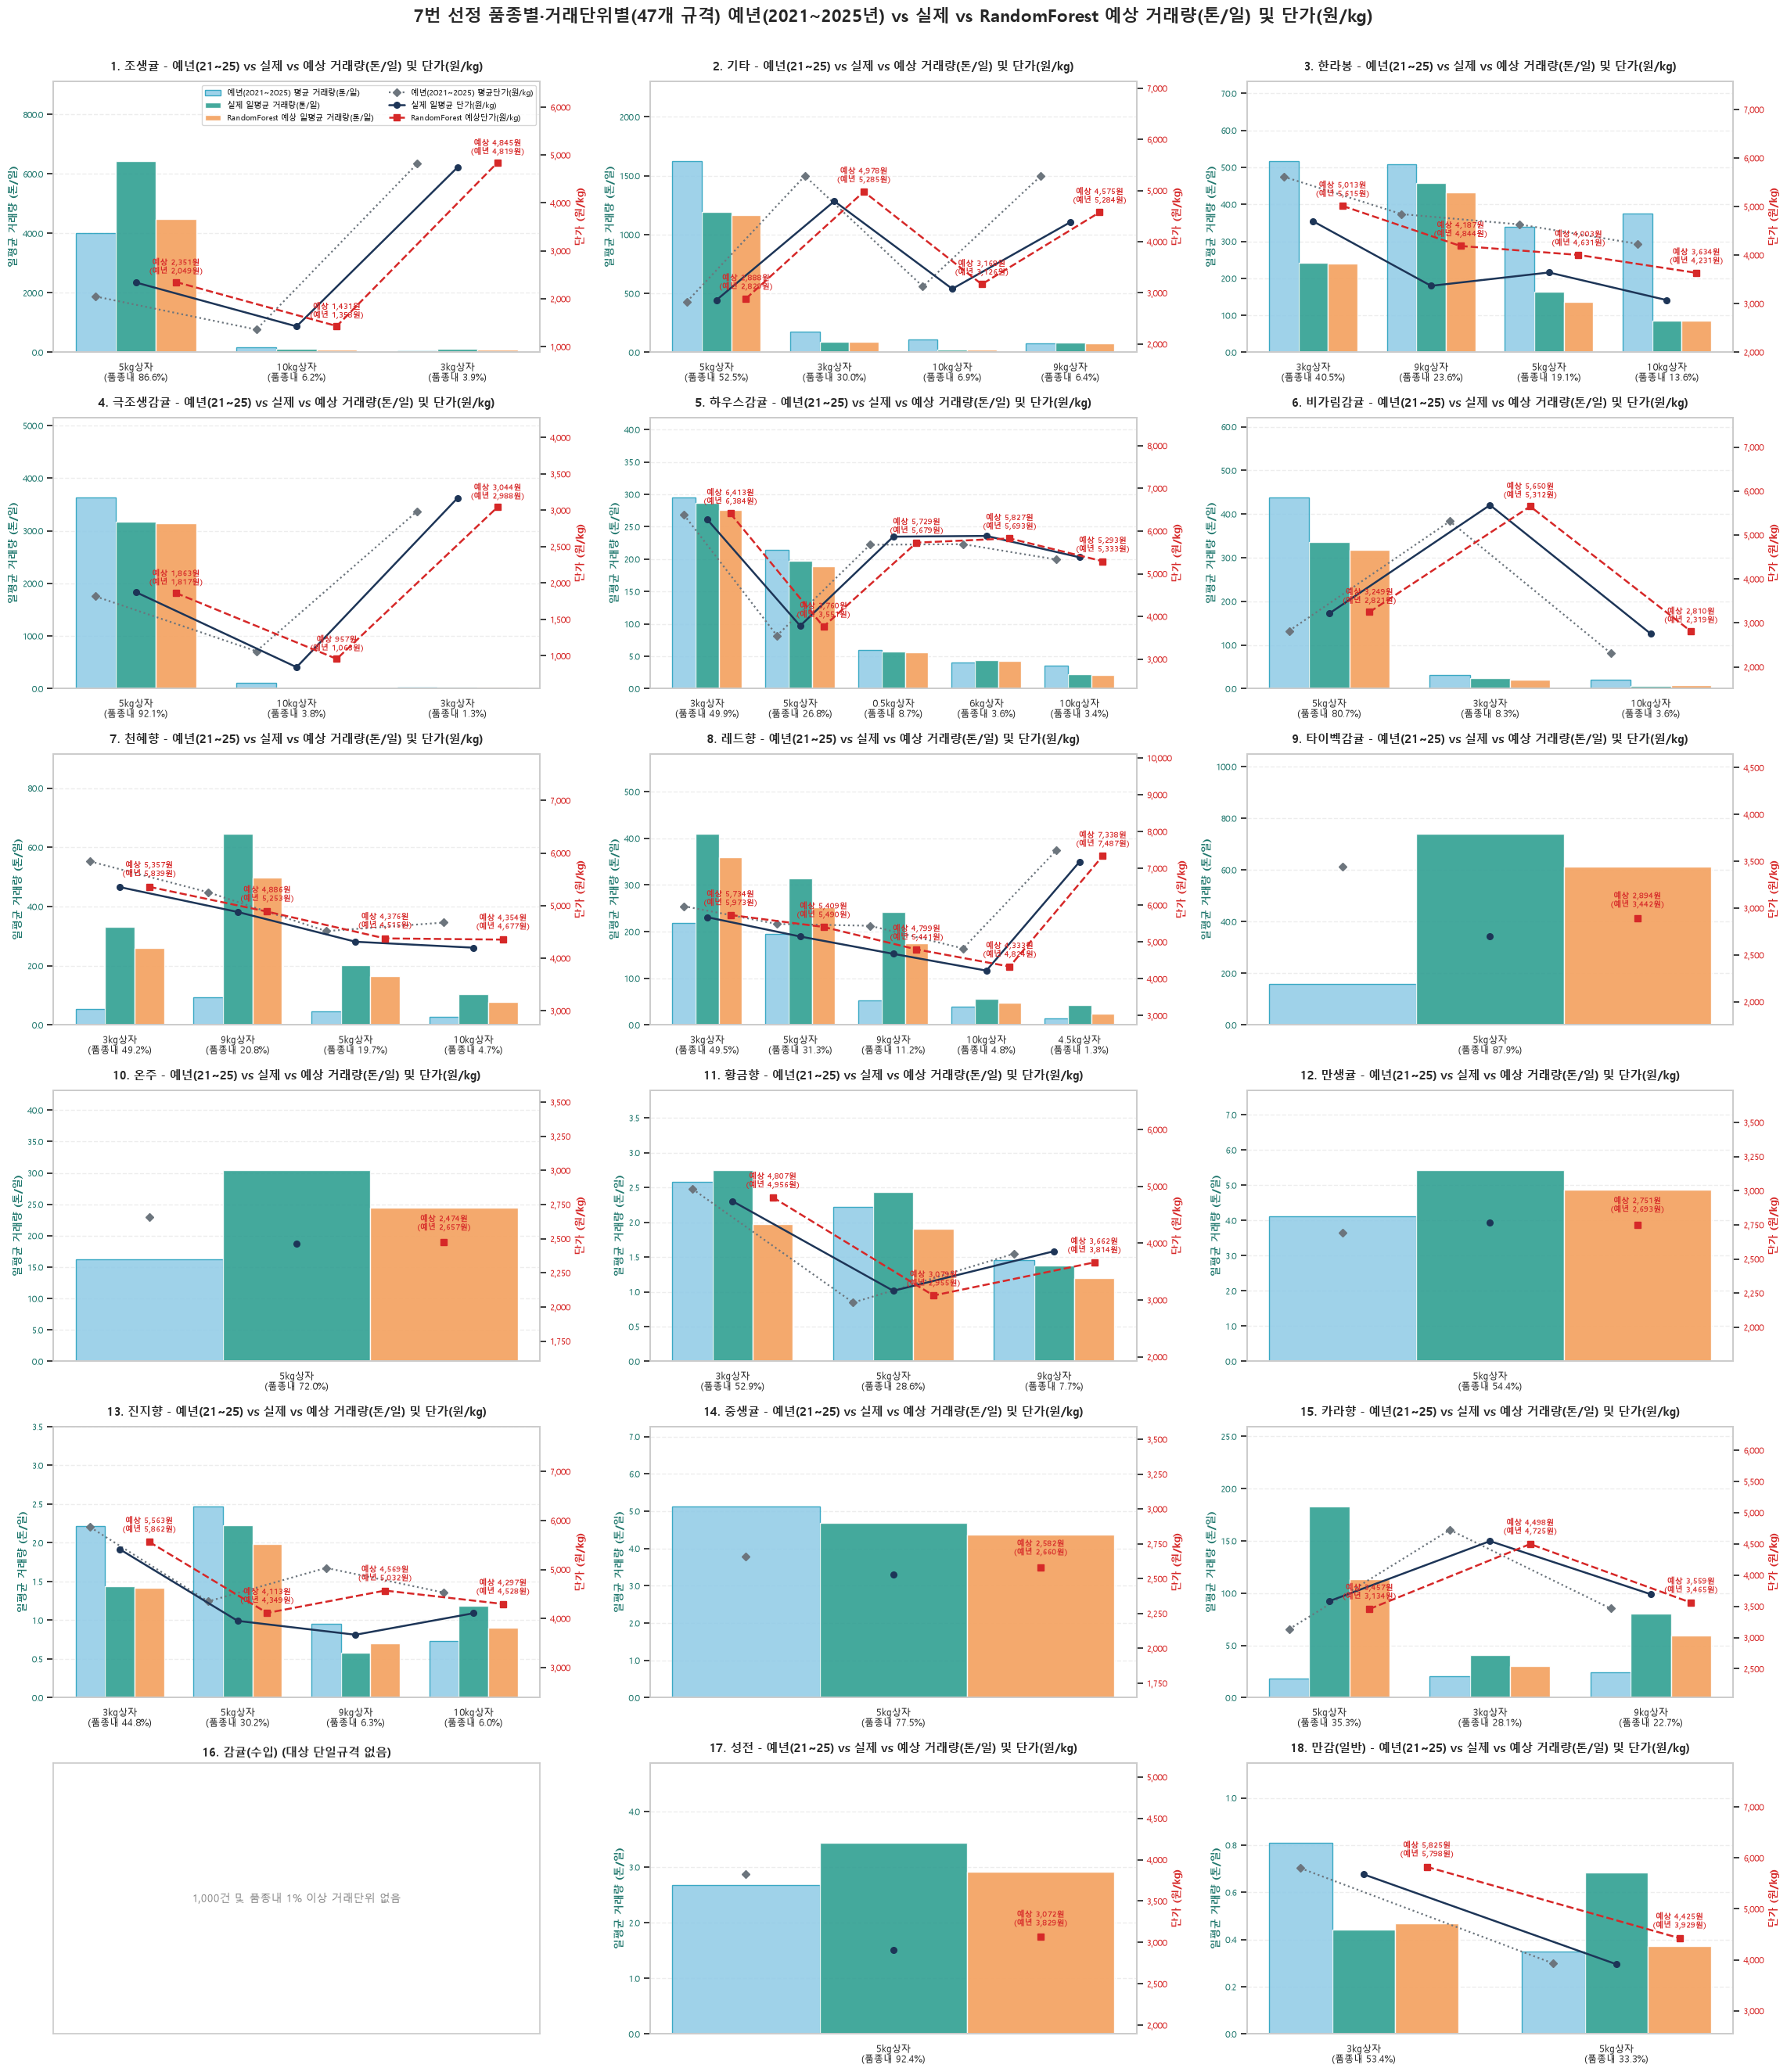

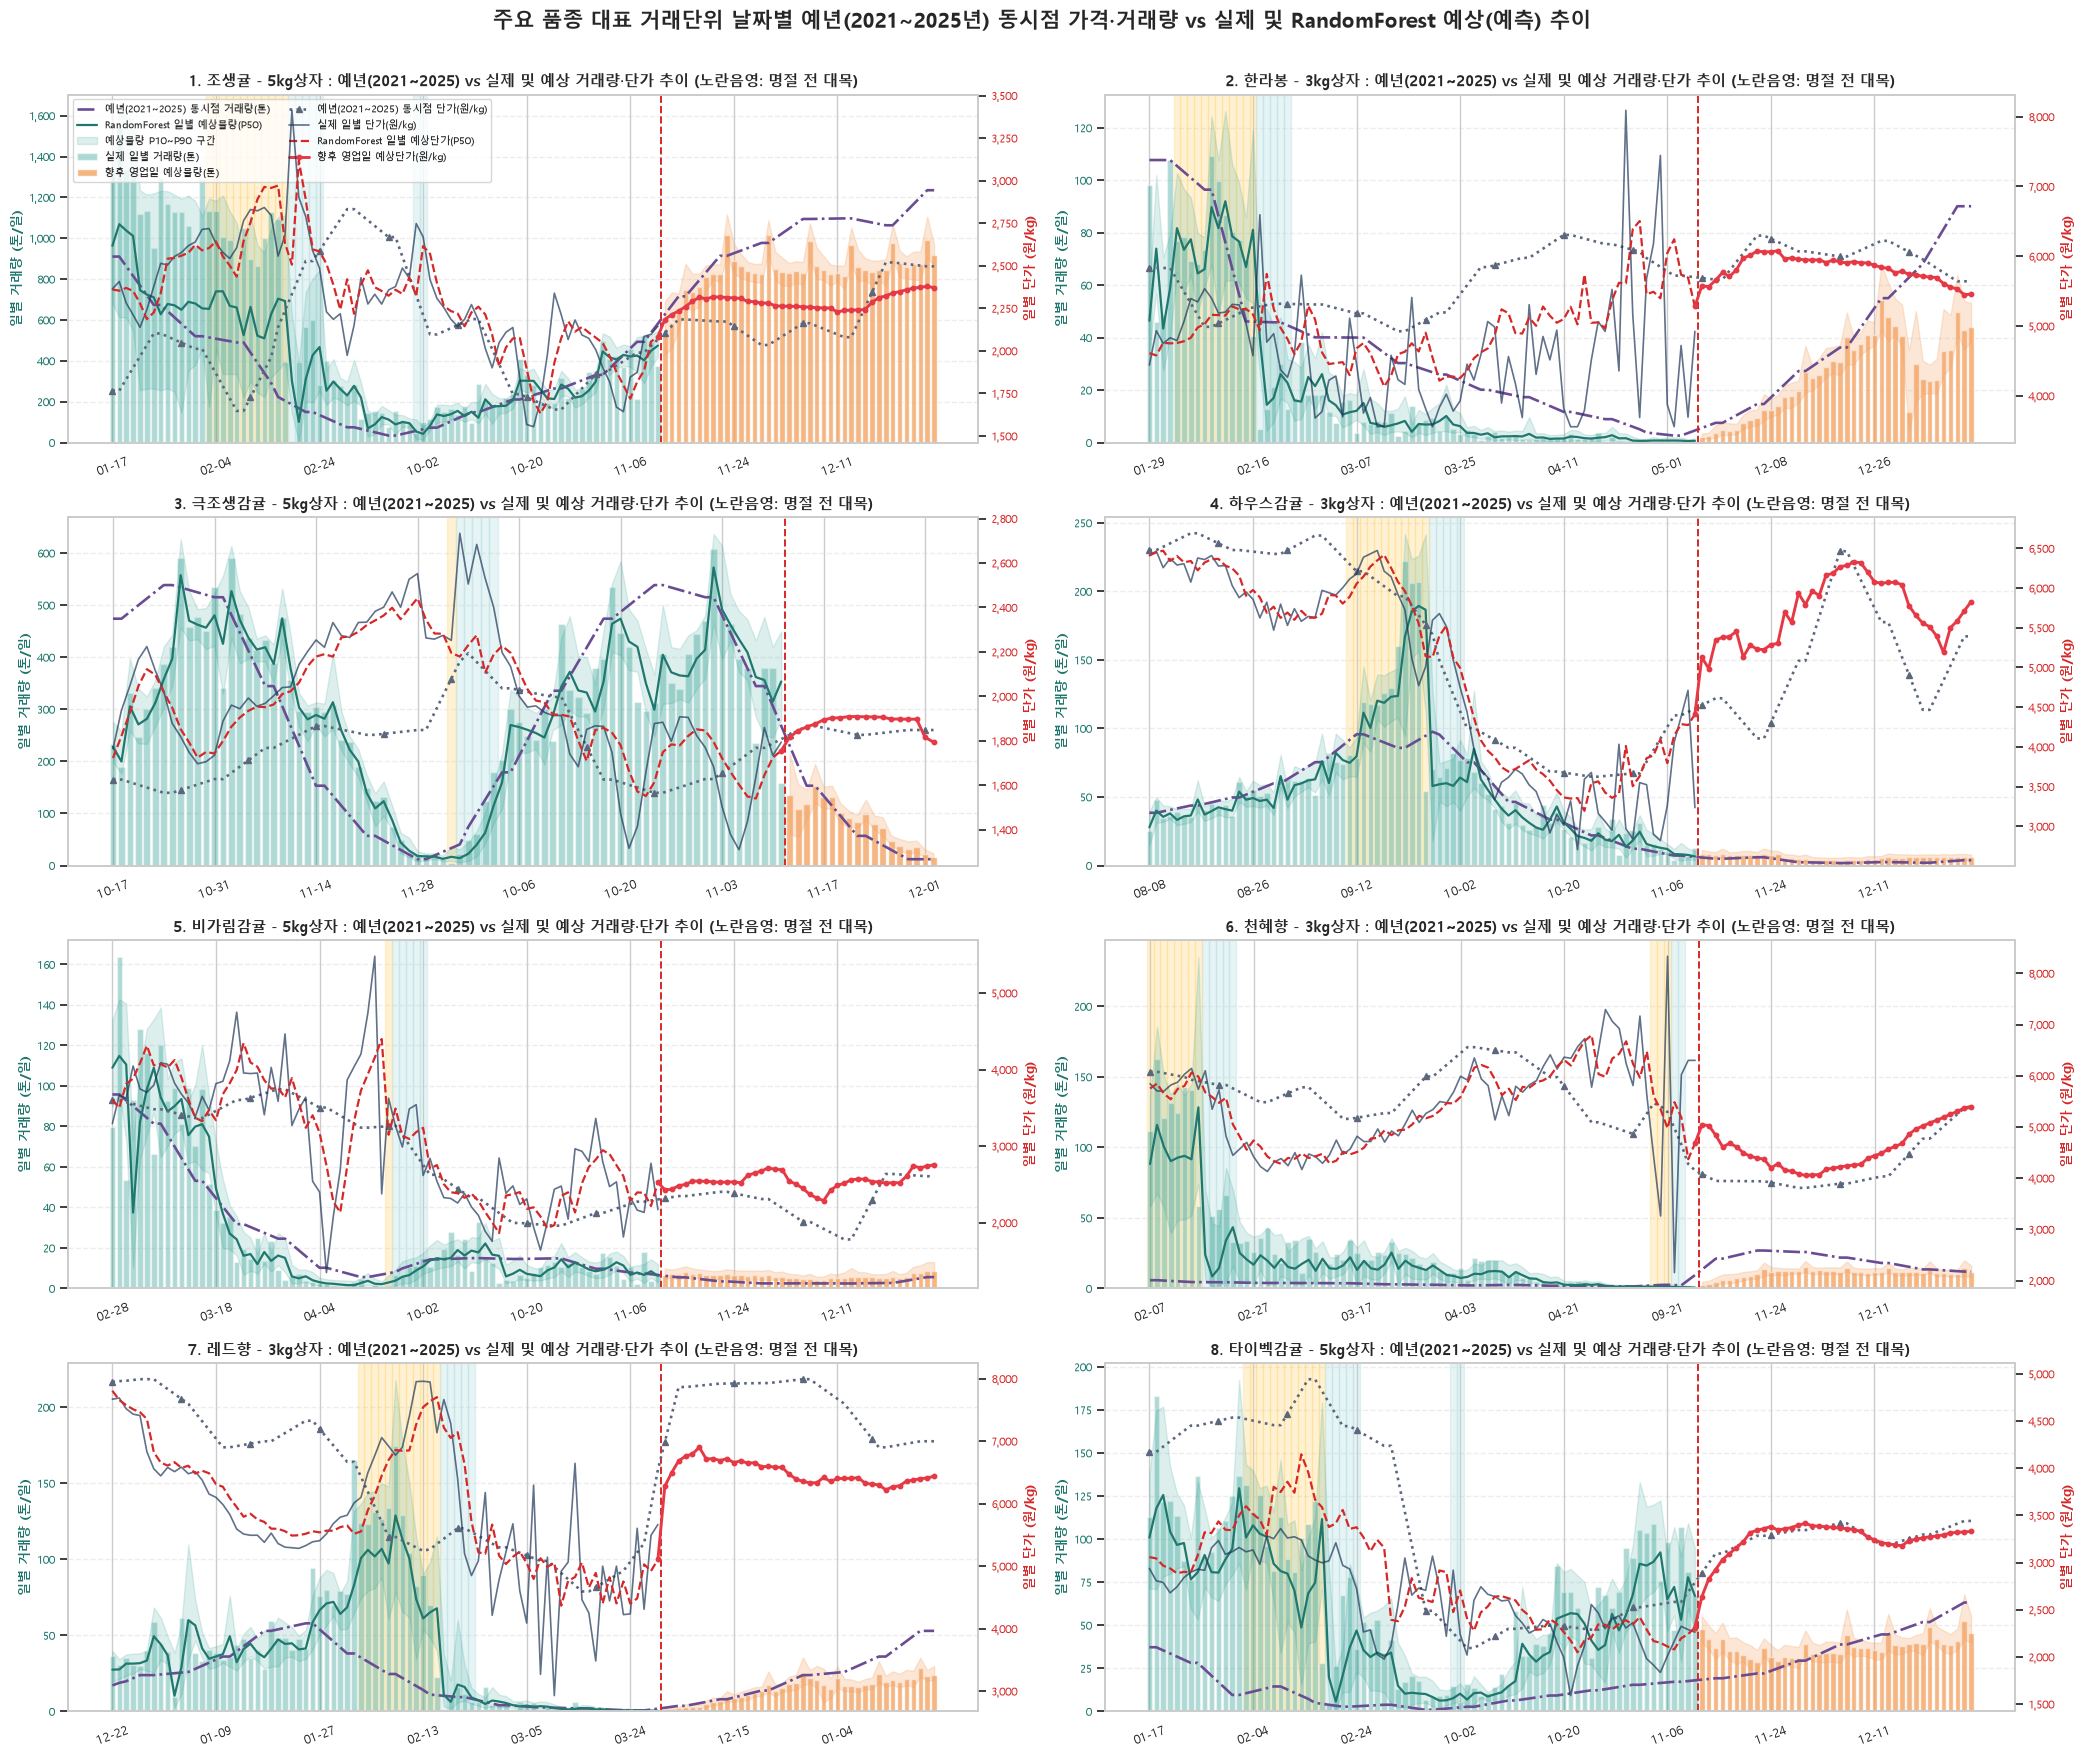

In [6]:
# 1) 18개 품종별 상위 거래단위(47개 규격) 예년(2021~2025년) vs 실제 vs RandomForest 예상(예측) 거래량(톤/일) 및 단가(원/kg) 비교 그래프 (6행 x 3열)
ncols_p = 3
nrows_p = int(np.ceil(len(variety_order) / ncols_p))
fig, axes = plt.subplots(nrows_p, ncols_p, figsize=(23, nrows_p * 4.4))
axes = axes.flatten()

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    sub_g = group_eval_df[group_eval_df['품종명'] == var_name].copy()

    if len(sub_g) == 0:
        ax1.set_title(f"{idx + 1}. {var_name} (대상 단일규격 없음)", fontsize=11, fontweight='bold')
        ax1.text(0.5, 0.5, '1,000건 및 품종내 1% 이상 거래단위 없음', ha='center', va='center', fontsize=10, color='gray')
        ax1.set_xticks([])
        ax1.set_yticks([])
        continue

    x_pos = np.arange(len(sub_g))
    w = 0.25
    ax1.bar(x_pos - w, sub_g['_hist_vol'], width=w, color='#8ECAE6', edgecolor='#219EBC', alpha=0.85, label='예년(2021~2025) 평균 거래량(톤/일)')
    ax1.bar(x_pos, sub_g['_act_vol'], width=w, color='#2A9D8F', alpha=0.88, label='실제 일평균 거래량(톤/일)')
    ax1.bar(x_pos + w, sub_g['_pred_vol'], width=w, color='#F4A261', alpha=0.92, label='RandomForest 예상 일평균 거래량(톤/일)')

    ax1.set_title(f"{idx + 1}. {var_name} - 예년(21~25) vs 실제 vs 예상 거래량(톤/일) 및 단가(원/kg)", fontsize=10.8, fontweight='bold', pad=10)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(
        [f"{r['거래단위']}\n(품종내 {r['품종내 비중']})" for _, r in sub_g.iterrows()],
        fontsize=8.5
    )
    ax1.set_ylabel('일평균 거래량 (톤/일)', color='#1F776D', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#1F776D', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.1f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    max_v = max(sub_g['_hist_vol'].max(), sub_g['_act_vol'].max(), sub_g['_pred_vol'].max())
    ax1.set_ylim(0, max_v * 1.42 if max_v > 0 else 1)

    ax2 = ax1.twinx()
    ax2.plot(x_pos - w, sub_g['_hist_prc'], color='#6C757D', marker='D', linestyle=':', linewidth=1.6, markersize=5.0, label='예년(2021~2025) 평균단가(원/kg)')
    ax2.plot(x_pos, sub_g['_act_prc'], color='#1D3557', marker='o', linewidth=1.8, markersize=5.5, label='실제 일평균 단가(원/kg)')
    ax2.plot(x_pos + w, sub_g['_pred_prc'], color='#D62828', marker='s', linestyle='--', linewidth=1.8, markersize=5.5, label='RandomForest 예상단가(원/kg)')
    ax2.set_ylabel('단가 (원/kg)', color='#D62828', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#D62828', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)

    min_p = min(sub_g['_hist_prc'].min(), sub_g['_act_prc'].min(), sub_g['_pred_prc'].min())
    max_p = max(sub_g['_hist_prc'].max(), sub_g['_act_prc'].max(), sub_g['_pred_prc'].max())
    ax2.set_ylim(max(0, min_p * 0.65), max_p * 1.35)

    for xi, (_, r) in enumerate(sub_g.iterrows()):
        ax2.text(
            xi + w,
            r['_pred_prc'] + (max_p * 0.03),
            f"예상 {r['_pred_prc']:,.0f}원\n(예년 {r['_hist_prc']:,.0f}원)",
            ha='center',
            va='bottom',
            fontsize=7.0,
            fontweight='bold',
            color='#D62828'
        )

    if idx == 0:
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax1.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=7.2, ncol=2)

for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('7번 선정 품종별·거래단위별(47개 규격) 예년(2021~2025년) vs 실제 vs RandomForest 예상 거래량(톤/일) 및 단가(원/kg)', fontsize=15.5, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

# 2) 주요 8개 품종 대표 거래단위의 날짜별 시계열: 예년(2021~2025년) 가격·거래량 vs 실제 및 RandomForest 예상(예측) 가격·거래량 추이
rep_groups = [
    '조생귤_5kg상자', '한라봉_3kg상자', '극조생감귤_5kg상자', '하우스감귤_3kg상자',
    '비가림감귤_5kg상자', '천혜향_3kg상자', '레드향_3kg상자', '타이벡감귤_5kg상자'
]

fig2, axes2 = plt.subplots(4, 2, figsize=(21, 17.5))
axes2 = axes2.flatten()

for idx, gid in enumerate(rep_groups):
    ax1 = axes2[idx]
    sub_hist = eval_daily[eval_daily['group_id'] == gid].sort_values('date').tail(80).copy()
    sub_fut = future_daily_df[future_daily_df['group_id'] == gid].sort_values('date').head(40).copy()

    dates_hist = sub_hist['date'].dt.strftime('%m-%d').tolist()
    dates_fut = sub_fut['date'].dt.strftime('%m-%d').tolist()
    all_d_labels = dates_hist + dates_fut
    all_periods = sub_hist['holiday_period'].tolist() + sub_fut['holiday_period'].tolist()

    x_h = np.arange(len(sub_hist))
    x_f = np.arange(len(sub_hist), len(all_d_labels))
    x_all = np.arange(len(all_d_labels))

    # 예년(2021~2025년) 동시점 거래량(톤) 및 단가(원/kg) 시계열 결합 (주간 전환 경계 5일 이동평균 완충)
    hist_vol_series = pd.Series(
        sub_hist['hist_wk_vol_ton'].tolist() + sub_fut['hist_wk_vol_ton'].tolist()
    ).rolling(5, min_periods=1, center=True).mean().values
    hist_prc_series = pd.Series(
        sub_hist['hist_wk_prc_kg'].tolist() + sub_fut['hist_wk_prc_kg'].tolist()
    ).rolling(5, min_periods=1, center=True).mean().values

    # 설날/추석 전후 구간 배경 하이라이트
    for xi, hp in enumerate(all_periods):
        if '전(' in hp:
            ax1.axvspan(xi - 0.5, xi + 0.5, color='#FFD166', alpha=0.28)
        elif '후(' in hp:
            ax1.axvspan(xi - 0.5, xi + 0.5, color='#A8DADC', alpha=0.28)

    ax1.bar(x_h, sub_hist['volume_ton'], color='#2A9D8F', alpha=0.38, width=0.8, label='실제 일별 거래량(톤)')
    ax1.plot(x_all, hist_vol_series, color='#6A4C93', linestyle='-.', linewidth=1.9, label='예년(2021~2025) 동시점 거래량(톤)')
    ax1.plot(x_h, sub_hist['pred_vol_p50'], color='#1F776D', linewidth=1.6, label='RandomForest 일별 예상물량(P50)')
    ax1.fill_between(x_h, sub_hist['pred_vol_p10'], sub_hist['pred_vol_p90'], color='#2A9D8F', alpha=0.16, label='예상물량 P10~P90 구간')

    ax1.bar(x_f, sub_fut['pred_vol_p50'], color='#F4A261', alpha=0.78, width=0.8, label='향후 영업일 예상물량(톤)')
    ax1.fill_between(x_f, sub_fut['pred_vol_p10'], sub_fut['pred_vol_p90'], color='#F4A261', alpha=0.25)

    ax1.axvline(len(sub_hist) - 0.5, color='#D62828', linestyle='--', linewidth=1.4)
    ax1.set_title(f"{idx + 1}. {gid.replace('_', ' - ')} : 예년(2021~2025) vs 실제 및 예상 거래량·단가 추이 (노란음영: 명절 전 대목)", fontsize=10.8, fontweight='bold')

    tick_step = max(1, len(all_d_labels) // 8)
    tick_idx = list(range(0, len(all_d_labels), tick_step))
    ax1.set_xticks(tick_idx)
    ax1.set_xticklabels([all_d_labels[i] for i in tick_idx], fontsize=8.5, rotation=20)
    ax1.set_ylabel('일별 거래량 (톤/일)', color='#1F776D', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#1F776D', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)

    ax2 = ax1.twinx()
    ax2.plot(x_all, hist_prc_series, color='#5C677D', linestyle=':', linewidth=1.9, marker='^', markevery=max(1, len(x_all)//12), markersize=4.2, label='예년(2021~2025) 동시점 단가(원/kg)')
    ax2.plot(x_h, sub_hist['unit_price_kg_clean'], color='#1D3557', linewidth=1.2, alpha=0.7, label='실제 일별 단가(원/kg)')
    ax2.plot(x_h, sub_hist['pred_prc_p50'], color='#D62828', linewidth=1.6, linestyle='--', label='RandomForest 일별 예상단가(P50)')
    if len(x_f) > 0:
        ax2.plot(
            np.append(x_h[-1], x_f),
            np.append(sub_hist['pred_prc_p50'].iloc[-1], sub_fut['pred_prc_p50'].values),
            color='#E63946',
            linewidth=2.1,
            marker='o',
            markersize=3.2,
            label='향후 영업일 예상단가(원/kg)'
        )
    ax2.set_ylabel('일별 단가 (원/kg)', color='#D62828', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#D62828', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)

    if idx == 0:
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=7.1, ncol=2)

fig2.suptitle('주요 품종 대표 거래단위 날짜별 예년(2021~2025년) 동시점 가격·거래량 vs 실제 및 RandomForest 예상(예측) 추이', fontsize=15, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

## 7. 일자별(Daily) Random Forest 모델 해석성(Interpretability) 분석: 1주 전·예년 해당 시점 변화량·날씨·명절 변수 중요도(Impurity %) 및 시차별 중요도
- **1주일 전 가격·거래량 및 예년 해당 시점의 가격·거래량 변화량**이 포함된 **33개 입력 변수의 불순도 감소 중요도(%)**와 **과거 영업일 및 예년 해당 시점(`t-1 ~ t-30, t-1년 동시점, t-7+Δ예년 변화량`) 시차별 중요도 비중**을 시각화합니다.

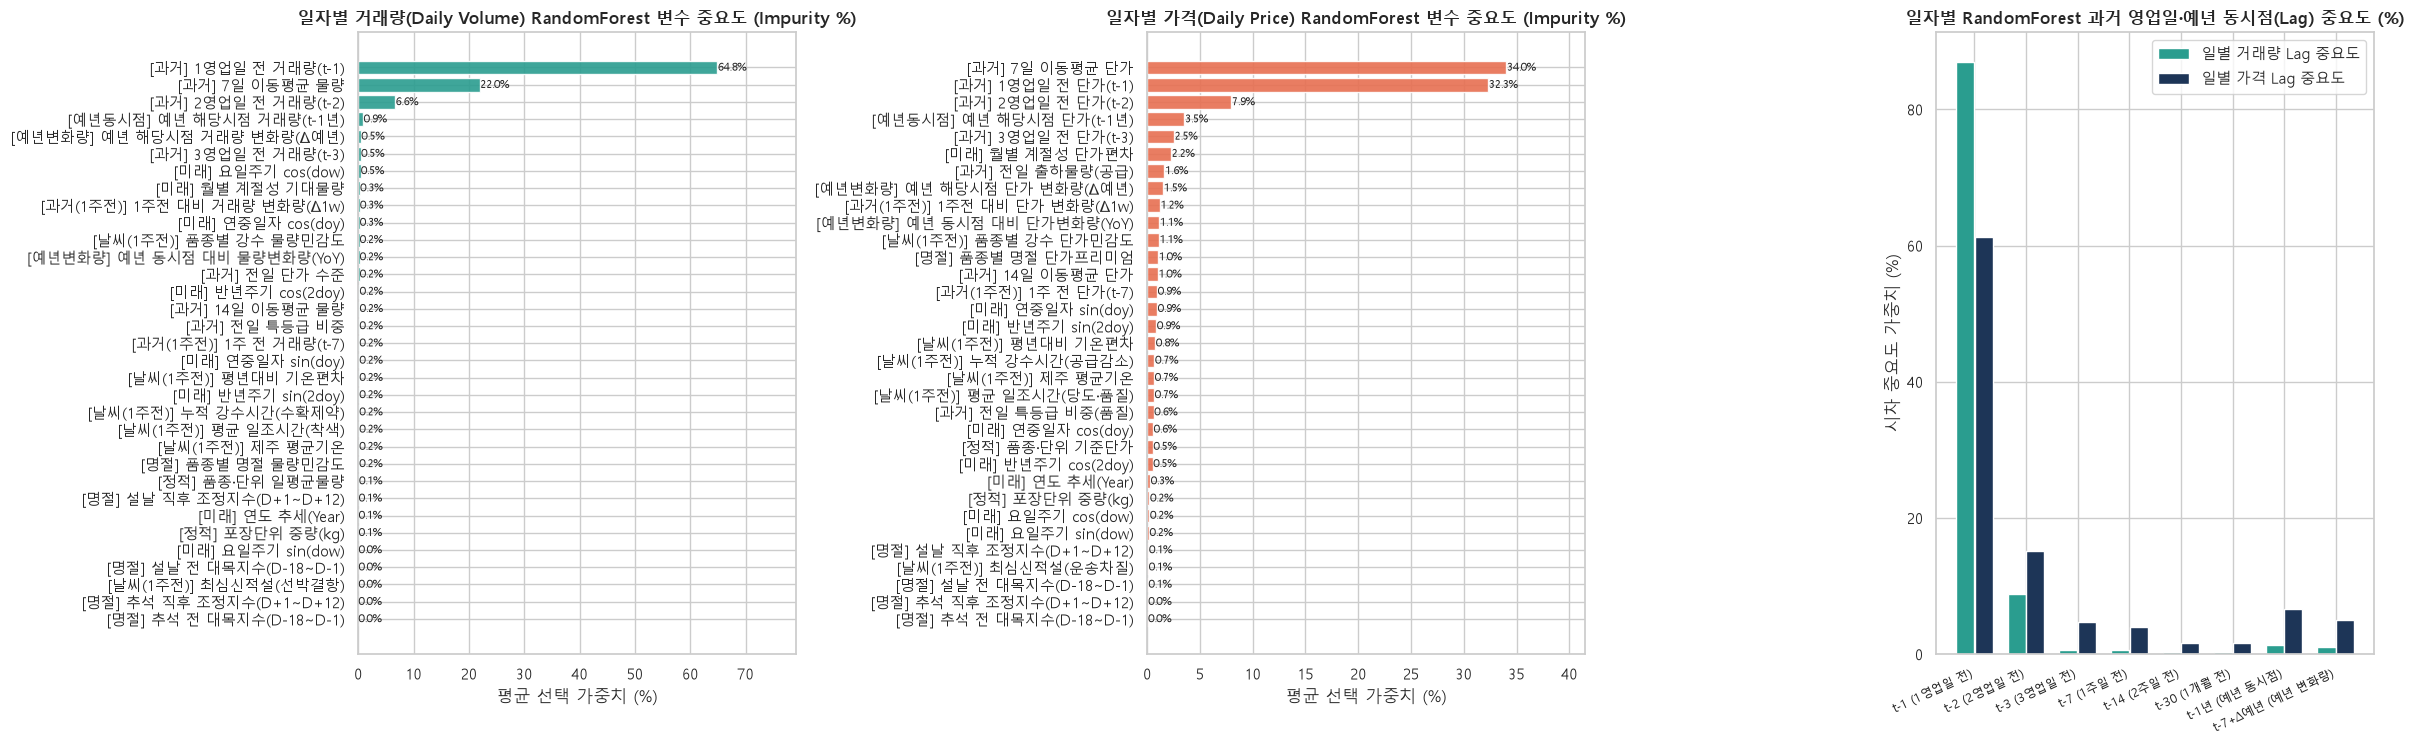

,과거·예년 시점(Lag),거래량 시차 중요도(%),가격 시차 중요도(%)
0,t-1 (1영업일 전),86.958427,61.291980
1,t-2 (2영업일 전),8.899500,15.075487
2,t-3 (3영업일 전),0.666394,4.774663
3,t-7 (1주일 전),0.645977,4.038110
4,t-14 (2주일 전),0.256096,1.618379
5,t-30 (1개월 전),0.269376,1.575318
6,t-1년 (예년 동시점),1.268502,6.654858
7,t-7+Δ예년 (예년 변화량),1.035728,4.971206


In [7]:
kor_vol_names = [
    '[정적] 품종·단위 일평균물량', '[정적] 포장단위 중량(kg)', '[미래] 월별 계절성 기대물량',
    '[명절] 설날 전 대목지수(D-18~D-1)', '[명절] 설날 직후 조정지수(D+1~D+12)',
    '[명절] 추석 전 대목지수(D-18~D-1)', '[명절] 추석 직후 조정지수(D+1~D+12)', '[명절] 품종별 명절 물량민감도',
    '[날씨(1주전)] 제주 평균기온', '[날씨(1주전)] 평년대비 기온편차', '[날씨(1주전)] 누적 강수시간(수확제약)',
    '[날씨(1주전)] 평균 일조시간(착색)', '[날씨(1주전)] 최심신적설(선박결항)', '[날씨(1주전)] 품종별 강수 물량민감도',
    '[미래] 연중일자 sin(doy)', '[미래] 연중일자 cos(doy)', '[미래] 반년주기 sin(2doy)', '[미래] 반년주기 cos(2doy)',
    '[미래] 요일주기 sin(dow)', '[미래] 요일주기 cos(dow)', '[미래] 연도 추세(Year)',
    '[과거] 1영업일 전 거래량(t-1)', '[과거] 2영업일 전 거래량(t-2)', '[과거] 3영업일 전 거래량(t-3)',
    '[과거(1주전)] 1주 전 거래량(t-7)', '[과거(1주전)] 1주전 대비 거래량 변화량(Δ1w)',
    '[예년동시점] 예년 해당시점 거래량(t-1년)', '[예년변화량] 예년 해당시점 거래량 변화량(Δ예년)',
    '[예년변화량] 예년 동시점 대비 물량변화량(YoY)',
    '[과거] 7일 이동평균 물량', '[과거] 14일 이동평균 물량',
    '[과거] 전일 단가 수준', '[과거] 전일 특등급 비중'
]
kor_prc_names = [
    '[정적] 품종·단위 기준단가', '[정적] 포장단위 중량(kg)', '[미래] 월별 계절성 단가편차',
    '[명절] 설날 전 대목지수(D-18~D-1)', '[명절] 설날 직후 조정지수(D+1~D+12)',
    '[명절] 추석 전 대목지수(D-18~D-1)', '[명절] 추석 직후 조정지수(D+1~D+12)', '[명절] 품종별 명절 단가프리미엄',
    '[날씨(1주전)] 제주 평균기온', '[날씨(1주전)] 평년대비 기온편차', '[날씨(1주전)] 누적 강수시간(공급감소)',
    '[날씨(1주전)] 평균 일조시간(당도·품질)', '[날씨(1주전)] 최심신적설(운송차질)', '[날씨(1주전)] 품종별 강수 단가민감도',
    '[미래] 연중일자 sin(doy)', '[미래] 연중일자 cos(doy)', '[미래] 반년주기 sin(2doy)', '[미래] 반년주기 cos(2doy)',
    '[미래] 요일주기 sin(dow)', '[미래] 요일주기 cos(dow)', '[미래] 연도 추세(Year)',
    '[과거] 1영업일 전 단가(t-1)', '[과거] 2영업일 전 단가(t-2)', '[과거] 3영업일 전 단가(t-3)',
    '[과거(1주전)] 1주 전 단가(t-7)', '[과거(1주전)] 1주전 대비 단가 변화량(Δ1w)',
    '[예년동시점] 예년 해당시점 단가(t-1년)', '[예년변화량] 예년 해당시점 단가 변화량(Δ예년)',
    '[예년변화량] 예년 동시점 대비 단가변화량(YoY)',
    '[과거] 7일 이동평균 단가', '[과거] 14일 이동평균 단가',
    '[과거] 전일 출하물량(공급)', '[과거] 전일 특등급 비중(품질)'
]

imp_vol = pd.DataFrame({
    '변수명': kor_vol_names,
    '중요도(%)': vsn_weights_vol.mean(axis=0) * 100
}).sort_values('중요도(%)', ascending=True)

imp_prc = pd.DataFrame({
    '변수명': kor_prc_names,
    '중요도(%)': vsn_weights_prc.mean(axis=0) * 100
}).sort_values('중요도(%)', ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(24, 7.6))

axes[0].barh(imp_vol['변수명'], imp_vol['중요도(%)'], color='#2A9D8F', alpha=0.9)
axes[0].set_title('일자별 거래량(Daily Volume) RandomForest 변수 중요도 (Impurity %)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('평균 선택 가중치 (%)')
for i, v in enumerate(imp_vol['중요도(%)']):
    axes[0].text(v + 0.08, i, f"{v:.1f}%", va='center', fontsize=7.8)
axes[0].set_xlim(0, imp_vol['중요도(%)'].max() * 1.22)

axes[1].barh(imp_prc['변수명'], imp_prc['중요도(%)'], color='#E76F51', alpha=0.9)
axes[1].set_title('일자별 가격(Daily Price) RandomForest 변수 중요도 (Impurity %)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('평균 선택 가중치 (%)')
for i, v in enumerate(imp_prc['중요도(%)']):
    axes[1].text(v + 0.08, i, f"{v:.1f}%", va='center', fontsize=7.8)
axes[1].set_xlim(0, imp_prc['중요도(%)'].max() * 1.22)

attn_df = pd.DataFrame({
    '과거·예년 시점(Lag)': lag_Step_names,
    '거래량 시차 중요도(%)': attn_weights_vol.mean(axis=0) * 100,
    '가격 시차 중요도(%)': attn_weights_prc.mean(axis=0) * 100
})
x_a = np.arange(len(lag_Step_names))
axes[2].bar(x_a - 0.18, attn_df['거래량 시차 중요도(%)'], width=0.35, color='#2A9D8F', label='일별 거래량 Lag 중요도')
axes[2].bar(x_a + 0.18, attn_df['가격 시차 중요도(%)'], width=0.35, color='#1D3557', label='일별 가격 Lag 중요도')
axes[2].set_title('일자별 RandomForest 과거 영업일·예년 동시점(Lag) 중요도 (%)', fontsize=12, fontweight='bold')
axes[2].set_xticks(x_a)
axes[2].set_xticklabels(lag_Step_names, rotation=25, ha='right', fontsize=8.5)
axes[2].set_ylabel('시차 중요도 가중치 (%)')
axes[2].legend()

plt.tight_layout()
plt.show()
display(attn_df)